# 01 · Análise pré-exploratória do WANDS

Objetivo: entender a estrutura e a qualidade dos três arquivos de `dataset/` antes de definir o protocolo de avaliação e o sistema de busca.

Este notebook **só lê** os dados; nada em `dataset/` é alterado. Os achados principais são registrados no `DEVLOG.md`, e os que afetam a avaliação, no `EVALUATION.md`.

As conclusões deixam explícitas as **suposições** feitas e, para cada **escolha**, as alternativas possíveis.

Etapas:
1. Carga e visão geral (dimensões, tipos, nulos, chaves, duplicatas)
2. `product.csv`
3. `query.csv`
4. `label.csv` e raciocínio da divisão em treino, validação e teste
5. Pontos que afetam a avaliação (pooling e normalização de texto)

## TL;DR

Resumo para quem não vai ler o notebook inteiro. Cada ponto indica a etapa onde estão os números, as suposições e as alternativas.

**O que temos.** Os dados vêm de uma loja online de móveis e decoração (Wayfair). São cerca de 43 mil produtos, 480 buscas e 233 mil julgamentos feitos por pessoas, dizendo se um produto atende a uma busca. Cada julgamento (`label`) tem três níveis:
- **Exact:** o produto atende totalmente à busca.
- **Partial:** é o tipo certo de produto, mas erra um detalhe, como cor, tamanho ou material.
- **Irrelevant:** o produto não atende à busca.

### Principais descobertas

- **Os dados estão em bom estado.** Os arquivos abrem sem perda de linhas. Há poucas repetições: cerca de 1.600 julgamentos duplicados e 14 contraditórios, que removemos (Etapas 1 e 4.2).
- **Resposta perfeita é rara.** Só 11% dos julgamentos são Exact, e 63% são Partial. Uma em cada cinco buscas não tem nenhum produto Exact (Etapas 4.2 e 4.3).
- **O gabarito cobre só uma pequena parte do catálogo.** Uma busca típica tem cerca de 215 produtos julgados, 0,5% do catálogo. Um produto sem julgamento não é necessariamente ruim: só não foi avaliado. Isso pode baixar a nota de buscadores que encontram produtos pelo significado, e não pelas mesmas palavras, porque eles tendem a trazer mais produtos nunca julgados (Etapas 4.3 e 5.1).
- **Ter as palavras da busca não basta.** Os produtos Irrelevant têm em média 42% das palavras da busca, contra 67% dos Exact. Por isso precisamos de um modelo que ordene os resultados com outros sinais além das palavras (Etapa 5.1).
- **A categoria do produto ajuda, mas não pode virar filtro.** Os produtos Exact costumam estar na categoria da busca (74%), e os Irrelevant quase nunca (5%). Mas 26% dos Exact estão em outra categoria, e um filtro os esconderia. O sinal pode estar exagerado pela forma como os candidatos foram escolhidos para julgamento (Etapa 4.5).
- **Notas e número de avaliações de clientes não indicam se o produto atende à busca.** 85% dos produtos avaliados têm 4,5 ou 5 estrelas. Dentro de uma mesma busca, produtos com mais avaliações ou notas maiores não tendem a ser mais relevantes. Vamos testá-los no modelo, sem esperar ganho (Etapas 2.1, 4.7 e 4.8).
- **Algumas buscas usam palavras que o catálogo não tem.** São 36 buscas (7,5%), com erros de digitação ("ligth"), nomes de outras lojas ou palavras grudadas. Um buscador só por palavras não resolve esses casos, o que justifica testar uma busca por significado (Etapas 3.1 e 5.2).
- **Um produto pode reunir vários tamanhos ou cores.** Muitas camas, por exemplo, aparecem como um único produto nos tamanhos queen e king, e o nome quase nunca diz o tamanho. Tamanho e cor ficam na lista de atributos do produto (`product_features`), que por isso deve entrar no texto da busca (Etapa 2.5).
- **Os atributos são muito variados.** Há quase 8 mil tipos diferentes de atributo, a maioria em texto. A proposta é tratá-los como um único bloco de texto na busca, em vez de um campo para cada tipo (Etapa 2.5).
- **Parte dos produtos tem informação faltando.** 22% não têm avaliações de clientes e 14% não têm descrição. A categoria (`product_class` ou `category_hierarchy`) falta em 4% a 7% dos produtos. Preencher a categoria com o valor mais comum de produtos parecidos erraria em 6% dos casos em `product_class` e em 24% em `category_hierarchy`, então deixamos o campo vazio (Etapas 1, 2.3 e 2.4).

### O que decidimos

- **Como separar os dados.** Uma busca sem nenhum produto relevante ficou de fora. As 479 restantes foram sorteadas em três grupos: 60% para treinar o modelo, 20% para comparar versões (validação) e 20% para o teste final. Cada busca fica inteira em um só grupo, para simular buscas que o sistema nunca viu. Os três grupos têm a mesma mistura de buscas com muitos e poucos produtos julgados (Etapa 4.6).
- **O teste final roda uma única vez**, depois de escolher o sistema na validação. Assim a nota final não é inflada por ajustes feitos olhando o teste.
- **Como medir a qualidade.** A nota principal (NDCG@10) avalia os 10 primeiros resultados de cada busca. Um produto Exact vale 2 pontos, um Partial vale 1, e os resultados mais no topo pesam mais. A nota vai de 0 a 1, e 1 é a melhor ordem possível. Ao lado, medimos quantos produtos Exact o buscador encontra entre os 100 primeiros candidatos e em que posição aparece o primeiro deles (`docs/EVALUATION.md`).
- **Produto sem julgamento conta como irrelevante**, que é a opção mais cautelosa. Junto, mostramos quantos dos 10 primeiros resultados foram julgados, para saber quanto a nota depende dessa regra.

### Próximos passos

- Construir o primeiro buscador por palavras (BM25, o método clássico) e medi-lo na validação.
- Comparar com uma busca por significado, com a combinação das duas e com um modelo de ranking que reordene os resultados.
- Ainda falta definir como saber se a diferença entre dois sistemas é real ou acaso.

## O que as fontes do WANDS dizem

Antes de olhar os dados, resumimos o que os autores documentaram. Isso muda a leitura de várias análises abaixo.

**Fontes**
- Artigo: Chen, Liu, Liu, Sun, Baltrunas e Schroeder, *WANDS: Dataset for Product Search Relevance Assessment*, ECIR 2022. [Preprint lido aqui](https://easychair.org/publications/preprint/wm4R) e [versão publicada](https://link.springer.com/chapter/10.1007/978-3-030-99736-6_9), que não conseguimos abrir.
- [Repositório oficial](https://github.com/wayfair/WANDS), com o dataset e as colunas.
- [Diretrizes de anotação](https://github.com/wayfair/WANDS/blob/main/Product%20Search%20Relevance%20Annotation%20Guidelines.pdf), o manual seguido por quem julgou os pares.
- [Post da Wayfair](https://aboutwayfair.com/careers/tech-blog/wayfair-releases-wands-the-largest-and-richest-publicly-available-dataset-for-e-commerce-product-search-relevance) sobre o lançamento.

### O que significa cada `label`

| `label` | Definição das diretrizes | Exemplo das diretrizes |
|---|---|---|
| Exact | O produto atende totalmente à busca. | "farmhouse cabinet" e um armário em estilo farmhouse |
| Partial | O produto é do tipo procurado, mas não atende aos modificadores da busca, como material, tamanho ou público. | "wire basket with dividers" e um cesto de arame sem divisórias |
| Irrelevant | O produto não é relevante para a busca. | "salon chair" e um tapete antifadiga para salão |

### Como os autores avaliaram

- Métrica: nDCG@10, com notas Exact = 1,0, Partial = 0,5 e Irrelevant = 0,0.
- Sistemas: BM25 sobre título e descrição, ordem aleatória e misturas dos dois, para mostrar que o dataset distingue sistemas melhores de piores.
- O objetivo era avaliar o dataset, não os modelos. O texto não traz os valores de nDCG, só um gráfico.

### Suposições dos autores

- **Completude:** os autores supõem que a seleção de candidatos encontrou "a maioria dos produtos relevantes" e admitem que a completude absoluta é impossível. **Logo, um produto sem rótulo não é necessariamente irrelevante.**
- Produtos adicionados ao carrinho são uma boa aproximação de produtos relevantes.

### O que as fontes não informam

- De qual fonte veio cada par.
- Por que `label.csv` tem pares repetidos e com rótulos diferentes.
- Se `query_class` é exatamente a saída do modelo de classificação de queries.
- Uma divisão oficial em treino, validação e teste: o artigo fala em dados de treino e avaliação, mas o README do repositório não traz nenhuma.

**Conferência:** os totais da Tabela 5 do artigo somam 25.614 Exact, 146.633 Partial e 61.201 Irrelevant, os mesmos números das linhas de `label.csv` antes da deduplicação.


## Setup

In [1]:
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from wands_search import data, plots, profiling, split

plots.apply_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)

print("pandas", pd.__version__, "| numpy", np.__version__)
print("data dir:", data.DEFAULT_DATA_DIR)

pandas 3.1.1 | numpy 2.5.4
data dir: /Users/Work/development_personal/ml_challenge/dataset


## Etapa 1 · Carga e visão geral

A carga usa `wands_search.data`, que lê os TSV e renomeia `category hierarchy` para `category_hierarchy` **apenas na carga**, sem alterar o arquivo bruto.

Também comparamos o número de linhas lidas pelo pandas com o número de linhas do arquivo: uma diferença indicaria problema de parse (por exemplo, aspas ou quebras de linha dentro de `product_description`).

In [2]:
tables = data.load_all()
products, queries, labels = tables["product"], tables["query"], tables["label"]

for name, df in tables.items():
    n_lines = profiling.count_data_lines(data.DEFAULT_DATA_DIR / data.FILENAMES[name])
    print(f"{name:8s} rows_read={len(df):>7,}  file_lines={n_lines:>7,}  columns={df.shape[1]}")

product  rows_read= 42,994  file_lines= 42,994  columns=9
query    rows_read=    480  file_lines=    480  columns=3
label    rows_read=233,448  file_lines=233,448  columns=4


**Conclusões:** os três arquivos são lidos sem perda: o número de linhas lidas é igual ao do arquivo (42.994 produtos, 480 queries e 233.448 rótulos). O separador por tab funciona sem tratamento de aspas.

**Fonte externa:** `pd.read_csv(..., sep="\t")` é a forma de abrir os arquivos sugerida no repositório oficial do WANDS, no [notebook de exemplo `read_dataset.ipynb`](https://github.com/wayfair/WANDS/blob/main/read_dataset.ipynb).

**Suposições**
- Número de linhas igual significa leitura correta. Essa checagem não detecta colunas deslocadas dentro de uma linha.

**Escolhas e alternativas**
- **Escolha:** ler os arquivos como TSV, com as opções padrão do pandas. **Alternativas:** desligar o tratamento de aspas (`quoting=csv.QUOTE_NONE`); converter os arquivos para vírgula, que descartamos porque `product_description` tem muitas vírgulas.

### Amostra de cada tabela

Cinco linhas aleatórias de cada tabela, com seed fixa, para vermos como os dados são. Textos longos aparecem cortados em 120 caracteres.

In [3]:
SAMPLE_SEED = 42

for name, df in tables.items():
    print(f"\n=== {name} ===")
    display(df.sample(5, random_state=SAMPLE_SEED))


=== product ===


,product_id,product_name,product_class,category_hierarchy,product_description,product_features,rating_count,average_rating,review_count
32193,32193,woven wire basket,"Boxes, Bins, Baskets, & Buckets",Storage & Organization / Storage Containers & Drawers / All Storage Containers,NaN,overalldepth-fronttoback:18|producttype : basket|features : stackable|overallheight-toptobottom:11.25|overalldepth-f...,21.0,5.0,19.0
21379,21379,scallop nightstand,Kids Nightstands,Baby & Kids / Toddler & Kids Bedroom Furniture / Kids Nightstands / Green Kids Nightstands,the scallop collection shows off its charming and lovely design with the scallop end table . this piece portrays an ...,framematerialdetails : mdf and plywood|theme : neutral|framematerial : manufactured wood|overallheight-toptobottom:2...,2.0,5.0,2.0
42275,42275,ybm home stainless steel colander,"Strainers, Colanders, & Salad Spinners","Kitchen & Tabletop / Kitchen Utensils & Tools / Colanders, Strainers, & Salad Spinners",this stainless steel colander with side handles will come in handy in your busy kitchen . the raised base keeps food...,overalldepth-fronttoback:11|overallproductweight:0.68|producttype : colander|overallproductweight:0.56|overallwidth-...,26.0,4.5,15.0
29885,29885,oneida 2 piece stainless steel strainer set,"Strainers, Colanders, & Salad Spinners","Kitchen & Tabletop / Kitchen Utensils & Tools / Colanders, Strainers, & Salad Spinners",NaN,producttype : strainer set|materialfinish : stainless steel|warrantylength : lifetime|material : stainless steel|rea...,1.0,5.0,1.0
8194,8194,ryland platform bed frame,Bed Frames|Beds,NaN,update the look of your room by adding the upholstered platform bed frame . this tailored platform frame creates a s...,color : black|overallwidth-sidetoside:60|overalllength-headtotoe:75|overallheight-toptobottom:15|legheight-toptobott...,2659.0,4.5,1676.0



=== query ===


,query_id,query,query_class
73,73,certified international melamine,Plates & Saucers
414,420,tile backsplash,Floor & Wall Tile
394,400,small ladies rocker swivel recliner,Recliners
277,281,brunk ship wheel,Decorative Objects
399,405,queen ann style living room chair,Accent Chairs



=== label ===


,id,query_id,product_id,label
67535,67686,26,14949,Partial
96482,96634,157,31490,Irrelevant
74096,74247,78,24497,Partial
226055,226622,123,38368,Irrelevant
60935,61086,5,1701,Exact


**Conclusões:** os ids não seguem a posição da linha (por exemplo, a linha 414 de `query.csv` tem `query_id` 420). Os cruzamentos entre tabelas devem usar sempre o id.

### Tipos e nulos por coluna

In [4]:
for name, df in tables.items():
    print(f"\n=== {name} ===")
    display(profiling.column_overview(df))


=== product ===


,dtype,nulls,null_pct,distinct
product_id,int64,0,0.00,42994
product_name,str,0,0.00,42577
product_class,str,2852,6.63,860
category_hierarchy,str,1556,3.62,1623
product_description,str,6008,13.97,33836
product_features,str,0,0.00,42979
rating_count,float64,9452,21.98,2861
average_rating,float64,9452,21.98,9
review_count,float64,9452,21.98,2310



=== query ===


,dtype,nulls,null_pct,distinct
query_id,int64,0,0.00,480
query,str,0,0.00,480
query_class,str,6,1.25,188



=== label ===


,dtype,nulls,null_pct,distinct
id,int64,0,0.0,233448
query_id,int64,0,0.0,480
product_id,int64,0,0.0,42986
label,str,0,0.0,3


**Conclusões**

**Nulos em `product.csv`:**
- `product_description`: 14% nulo. Próxima etapa: verificar se esses produtos têm as outras informações (`product_name`, `product_class` e `product_features`).
- `rating_count`, `average_rating` e `review_count`: 22% nulos. Próxima etapa: são nulos para os mesmos produtos? Podemos tratá-los como produtos novos?
- `product_class`: 6,6% nulo. Próxima etapa: podemos deduzir a partir de outras colunas?
- `category_hierarchy`: 3,6% nulo. Próxima etapa: podemos deduzir a partir de outras colunas?
- `product_features`: não tem nulos.

**Nulos em `query.csv`:**
- `query_class`: 6 queries nulas (1,25%). Próxima etapa: quais são essas queries?

**Cardinalidade:**
- São 860 `product_class` contra 188 `query_class`. Próxima etapa: são os mesmos valores?
- `average_rating` tem só 9 valores distintos. Próxima etapa: qual é a escala?

### Unicidade das chaves e linhas duplicadas

In [5]:
checks = {
    "product_id unique in product": products["product_id"].is_unique,
    "query_id unique in query": queries["query_id"].is_unique,
    "id unique in label": labels["id"].is_unique,
    "(query_id, product_id) unique in label": not labels.duplicated(["query_id", "product_id"]).any(),
}
for k, v in checks.items():
    print(f"{k:45s} {v}")

print()
print("duplicate rows in product (ignoring product_id):", products.drop(columns="product_id").duplicated().sum())
print("duplicate rows in query (ignoring query_id):    ", queries.drop(columns="query_id").duplicated().sum())
print("duplicate rows in label (ignoring id):          ", labels.drop(columns="id").duplicated().sum())

product_id unique in product                  True
query_id unique in query                      True
id unique in label                            True
(query_id, product_id) unique in label        False



duplicate rows in product (ignoring product_id): 0
duplicate rows in query (ignoring query_id):     0
duplicate rows in label (ignoring id):           1561


**Conclusões:** `product_id`, `query_id` e o `id` de `label.csv` são únicos. Não há produtos nem queries duplicados, mesmo ignorando o id. Já o par (query, produto) se repete em `label.csv`, o que investigamos a seguir.

**Suposições**
- "Duplicado" aqui significa a linha inteira igual. Produtos que repetem só `product_name` ou só `product_description` não entram nessa conta.

### Pares (query, produto) repetidos em `label.csv`

O par `(query_id, product_id)` não é único. Verificamos se as repetições são cópias exatas (mesmo rótulo) ou **conflitos** (rótulos diferentes para o mesmo par), porque um conflito exigiria uma regra de resolução antes de treinar e avaliar.

In [6]:
pair_stats = profiling.label_pair_stats(labels)
repeated = pair_stats[pair_stats["n_rows"] > 1]
same_label = repeated[repeated["n_labels"] == 1]
conflicting = repeated[repeated["n_labels"] > 1]

total_rows = len(labels)
extra_rows = total_rows - len(pair_stats)
exact_copy_rows = labels.drop(columns="id").duplicated().sum()
conflict_rows = (conflicting["n_labels"] - 1).sum()
assert exact_copy_rows + conflict_rows == extra_rows

print("PAIRS (query_id, product_id)")
print(f"  distinct pairs:                     {len(pair_stats):>7,}")
print(f"  pairs appearing more than once:     {len(repeated):>7,}")
print(f"    same label in all rows:           {len(same_label):>7,}")
print(f"    different labels (conflicting):   {len(conflicting):>7,}")
print(f"  max rows for a single pair:         {pair_stats['n_rows'].max():>7,}")
print(f"  queries with repeated pairs:        {repeated.index.get_level_values('query_id').nunique():>7,}")
print()
print("ROWS")
print(f"  total rows:                         {total_rows:>7,}")
print(f"  extra rows (total - distinct pairs):{extra_rows:>7,}")
print(f"    exact copies, ignoring id:        {exact_copy_rows:>7,}  (safe to drop)")
print(f"    rows with a differing label:      {conflict_rows:>7,}  (need a resolution rule)")

conflicts = profiling.conflicting_label_rows(labels)
display(conflicts)

PAIRS (query_id, product_id)
  distinct pairs:                     231,873
  pairs appearing more than once:       1,467
    same label in all rows:             1,453
    different labels (conflicting):        14
  max rows for a single pair:               5
  queries with repeated pairs:            121

ROWS
  total rows:                         233,448
  extra rows (total - distinct pairs):  1,575
    exact copies, ignoring id:          1,561  (safe to drop)
    rows with a differing label:           14  (need a resolution rule)


,id,query_id,product_id,label
0,65,0,31306,Irrelevant
1,21650,0,31306,Partial
2,1325,12,34349,Exact
3,21761,12,34349,Partial
4,21764,12,34349,Partial
5,2380,24,696,Exact
6,21853,24,696,Partial
7,11489,89,24413,Exact
8,22346,89,24413,Partial
9,13869,106,1990,Partial


**Conclusões**

**Duplicatas em `label.csv`:**
- 1.561 linhas são cópias exatas (mesma query, mesmo produto e mesmo rótulo, mudando só o `id`). Podem ser removidas sem perda.
- 14 pares (query, produto) têm rótulos diferentes, de 231.873 pares distintos. Proposta: excluir esses pares, já que não temos uma regra de negócio para decidir qual rótulo vale. Restariam 231.859 pares.

**Cobertura dos rótulos:**
- Só 8 dos 42.994 produtos nunca foram julgados em nenhuma query.
- Cada query, porém, tem em média ~483 produtos julgados (231.873 pares / 480 queries), cerca de 1,1% do catálogo. A mediana é bem menor, como mostra a Etapa 4. Para os demais produtos, não sabemos se são relevantes para aquela query.
- Próxima etapa: como tratar, na avaliação do retrieval, um produto retornado que não foi julgado para a query?

**Suposições**
- Cópias exatas são o mesmo julgamento repetido, não votos independentes. O artigo diz que cada linha já é o resultado de uma votação e não explica por que há pares repetidos.
- Excluir 14 pares não afeta a avaliação, porque são poucos diante de 231.873.

**Escolhas e alternativas**
- **Escolha:** excluir os pares com rótulos diferentes. **Alternativas:** manter o rótulo mais frequente (não resolve os empates); manter o menor rótulo, por cautela; manter o maior; usar a média dos ganhos.

### Distribuição de `label`

Quantas linhas de `label.csv` têm cada valor de `label`, depois de remover as 1.561 cópias exatas. Os 14 pares com rótulos diferentes ainda ficam aqui; a Etapa 4.2 recalcula a tabela sem eles.


In [7]:
labels_without_copies = labels.drop(columns="id").drop_duplicates()
print(f"rows before: {len(labels):,}")
print(f"rows after removing exact copies: {len(labels_without_copies):,}")

label_counts = labels_without_copies["label"].value_counts()
display(pd.DataFrame({"rows": label_counts, "pct": (label_counts / label_counts.sum() * 100).round(1)}))
print(f"null label: {labels_without_copies['label'].isna().sum()}")

rows before: 233,448
rows after removing exact copies: 231,887


,rows,pct
label,,
Partial,145684,62.8
Irrelevant,60724,26.2
Exact,25479,11.0


null label: 0


**Conclusões**

- `label` não tem nulos e é desbalanceado: das 231.887 linhas, 62,8% são Partial, 26,2% são Irrelevant e 11,0% são Exact.

**Suposições**
- Essa proporção vale para os pares (query, produto) julgados, não para o catálogo inteiro: só foram julgados os candidatos selecionados.
- Cópias exatas são o mesmo julgamento repetido, como assumido acima.
- Cada um dos 14 pares com rótulos diferentes conta uma vez por rótulo. São 28 linhas, poucas para mudar essa proporção.

**Escolhas e alternativas**
- **Escolha:** remover só as cópias exatas. **Alternativas:** contar as linhas como estão no arquivo; excluir também os pares com rótulos diferentes (Etapa 4.2); calcular a proporção por query, o que dá o mesmo peso a cada query.


## Etapa 2 · `product.csv`

Aqui respondemos as perguntas deixadas pela Etapa 1 sobre os produtos.

### 2.1 · Colunas numéricas de avaliação

Estas são as "features numéricas" que o desafio pede para usar no ranking. Queremos saber: os nulos são os mesmos produtos? Qual é a escala de `average_rating`? As contagens são muito concentradas em poucos produtos? As colunas são coerentes entre si (por exemplo, um produto ter mais reviews do que avaliações seria estranho)?

In [8]:
rating_columns = ["rating_count", "average_rating", "review_count"]
rating_nulls = products[rating_columns].isna()
print(f"all three columns null: {rating_nulls.all(axis=1).sum():>6,}")
print(f"any column null:        {rating_nulls.any(axis=1).sum():>6,}")

rated = products.dropna(subset=rating_columns)
display(rated[rating_columns].describe(percentiles=[0.5, 0.9, 0.99]).round(2))
print("average_rating values:")
display(rated["average_rating"].value_counts().sort_index().to_frame("products"))
print(f"rating_count == 0 among non-null:  {(rated['rating_count'] == 0).sum():>6,}")
print(f"review_count == 0 among non-null:  {(rated['review_count'] == 0).sum():>6,}")
print(f"review_count > rating_count:       {(rated['review_count'] > rated['rating_count']).sum():>6,}")

all three columns null:  9,452
any column null:         9,452


,rating_count,average_rating,review_count
count,33542.00,33542.00,33542.00
mean,430.27,4.53,284.25
std,2407.92,0.51,1539.61
min,1.00,1.00,0.00
50%,42.00,4.50,31.00
90%,748.00,5.00,495.00
99%,6123.85,5.00,3955.13
max,109226.00,5.00,61362.00


average_rating values:


,products
average_rating,
1.0,175
1.5,13
2.0,125
2.5,93
3.0,465
3.5,704
4.0,3568
4.5,17707
5.0,10692


rating_count == 0 among non-null:       0
review_count == 0 among non-null:     543
review_count > rating_count:            0


### Quantos produtos têm avaliação

Antes de olhar as notas, medimos quantos produtos de `product.csv` têm avaliação, ou seja, têm `rating_count` preenchido. Os gráficos seguintes usam só esses produtos.


,group,products,pct
0,with ratings,33542,78.0
1,without ratings,9452,22.0


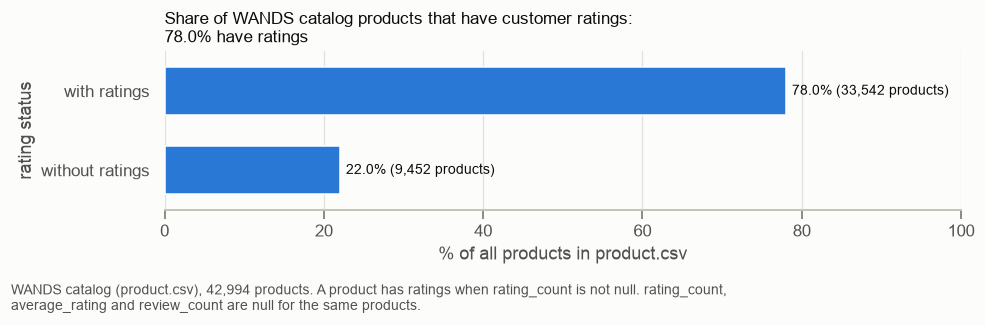

In [9]:
has_ratings = products["rating_count"].notna()
rating_coverage = pd.DataFrame({
    "group": ["with ratings", "without ratings"],
    "products": [has_ratings.sum(), (~has_ratings).sum()],
})
rating_coverage["pct"] = (rating_coverage["products"] / len(products) * 100).round(1)
display(rating_coverage)

fig, ax = plt.subplots(figsize=(9, 2.6))
sns.barplot(data=rating_coverage, y="group", x="pct", color=plots.SERIES_1, saturation=1, width=0.6, ax=ax)
ax.bar_label(ax.containers[0], padding=4, color=plots.PRIMARY_INK, fontsize=9,
             labels=[f"{row.pct:.1f}% ({row.products:,} products)" for row in rating_coverage.itertuples()])
ax.grid(axis="y", visible=False)
ax.set_xlim(0, 100)
ax.set_title(f"Share of WANDS catalog products that have customer ratings:\n{rating_coverage['pct'].iloc[0]:.1f}% have ratings")
ax.set_xlabel("% of all products in product.csv")
ax.set_ylabel("rating status")
fig.tight_layout()
plots.add_caption(fig, f"WANDS catalog (product.csv), {len(products):,} products. A product has ratings when rating_count "
                       "is not null. rating_count, average_rating and review_count are null for the same products.", width=115)
plt.show()

**Conclusões:** 33.542 produtos (78,0%) têm avaliação, e 9.452 (22,0%) não têm.

**Suposições**
- Nulo em `rating_count` significa "sem avaliação", não dado perdido. O dataset não confirma isso.


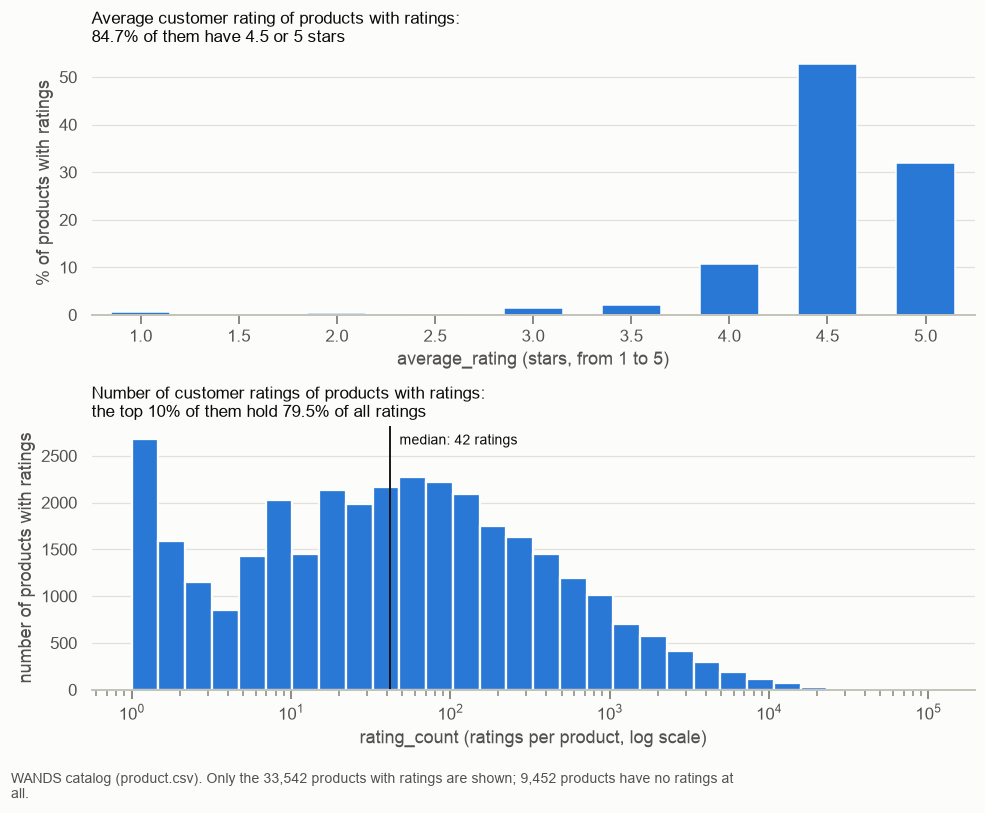

In [10]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 7))

rating_share = rated["average_rating"].value_counts(normalize=True).sort_index() * 100
high_rating_share = rating_share[rating_share.index >= 4.5].sum()
sns.barplot(x=rating_share.index.astype(str), y=rating_share.values, color=plots.SERIES_1, saturation=1, width=0.6, ax=top)
top.grid(axis="x", visible=False)
top.set_title(f"Average customer rating of products with ratings:\n{high_rating_share:.1f}% of them have 4.5 or 5 stars")
top.set_xlabel("average_rating (stars, from 1 to 5)")
top.set_ylabel("% of products with ratings")

sns.histplot(rated["rating_count"], log_scale=True, bins=30, color=plots.SERIES_1, alpha=1,
             edgecolor=plots.SURFACE, linewidth=1.5, ax=bottom)
bottom.grid(axis="x", visible=False)
top_10pct_share = rated["rating_count"].nlargest(round(len(rated) * 0.1)).sum() / rated["rating_count"].sum() * 100
bottom.set_title(f"Number of customer ratings of products with ratings:\nthe top 10% of them hold {top_10pct_share:.1f}% of all ratings")
bottom.set_xlabel("rating_count (ratings per product, log scale)")
bottom.set_ylabel("number of products with ratings")
plots.reference_line(bottom, rated["rating_count"].median(), f"median: {rated['rating_count'].median():.0f} ratings")

fig.tight_layout()
plots.add_caption(fig, f"WANDS catalog (product.csv). Only the {len(rated):,} products with ratings are shown; "
                       f"{len(products) - len(rated):,} products have no ratings at all.", width=115)
plt.show()

**Conclusões**

- `rating_count`, `average_rating` e `review_count` são nulas exatamente nos mesmos 9.452 produtos.
- Fora dos nulos, `rating_count` é sempre pelo menos 1, então nulo parece significar "sem avaliação".
- Não podemos afirmar que são produtos novos, porque o dataset não tem data. Proposta: criar uma feature "tem avaliação" em vez de imputar zero.
- `average_rating` vai de 1 a 5, em passos de 0,5. 85% dos produtos avaliados têm nota 4,5 ou 5, então a coluna distingue pouco os produtos.
- `rating_count` e `review_count` são muito concentradas: em `rating_count`, a mediana é 42, a média é 430 e o máximo é 109.226, e os 10% de produtos com mais avaliações têm 79,5% delas. Proposta: aplicar log antes de usar no ranking.
- As colunas são coerentes: `review_count` nunca passa de `rating_count`.

**Suposições**
- Nulo em `rating_count`, `average_rating` e `review_count` significa "sem avaliação", não dado perdido. O dataset não confirma isso.
- Essas colunas ajudam o ranking. A Etapa 2 só descreve as colunas; ainda não comparamos com `label`.

**Escolhas e alternativas**
- **Escolha:** criar uma feature "tem avaliação" e manter o nulo (proposta). **Alternativas:** imputar zero (confunde "sem avaliação" com nota baixa); imputar a mediana; deixar o modelo tratar o nulo, como fazem modelos de árvore.
- **Escolha:** aplicar log em `rating_count` e `review_count` (proposta). **Alternativas:** usar a posição do produto na ordenação (rank); não transformar, já que modelos de árvore só dependem da ordem dos valores.
- **Escolha:** usar `average_rating` como está. **Alternativas:** ajustar a nota pelo número de avaliações (média bayesiana), porque uma nota com poucas avaliações é menos confiável.

### O que isso muda para nós

Esta parte é a nossa interpretação, não um resultado medido. Só os números de `rating_count` vêm das saídas acima; a Etapa 2 ainda não compara essas colunas com `label`.

**Impacto no ranking**

- **A escala da feature pode atrapalhar:** a mediana de `rating_count` é 42, a média é 430 e o máximo é 109.226. Em valores brutos, a diferença entre 42 e 100 avaliações quase some perto desse máximo. O log corrige isso, porque a diferença passa a ser proporcional: ir de 10 para 100 pesa o mesmo que ir de 1.000 para 10.000.
  - O log importa para modelos sensíveis à escala, como regressão logística e redes neurais.
  - Em modelos de árvores, como o LambdaMART, o resultado praticamente não muda, porque eles só usam a ordem dos valores.
- **`average_rating` não é igualmente confiável em todos os produtos:** um 5,0 com 2 avaliações diz bem menos do que um 4,5 com 10.000. Por isso, vale dar as duas colunas ao modelo, em vez de usar `average_rating` sozinha.
- **Há risco de favorecer produtos populares:** se `rating_count` tiver peso alto, o modelo pode empurrar os produtos populares para o topo, mesmo quando outro atende melhor à query. Produtos sem avaliação ou com poucas avaliações ficariam em desvantagem.

**O que fazer**

- **Testar em vez de assumir:** a ablação do ranking deve comparar o modelo com e sem as colunas de avaliação, o que o desafio já pede. Ela mostra se `rating_count` melhora a ordenação medida com `label`.
- **Olhar a análise de erros:** vale conferir se os erros se concentram em produtos muito populares ou sem avaliação.
- **Cuidado com o sinal medido:** `label` diz se o produto atende à query, não se ele vende bem. Mesmo que a feature ajude pouco aqui, isso não prova que popularidade é inútil em produção, onde o objetivo também pode incluir vendas.


### 2.2 · `product_class` e `category_hierarchy`

Duas formas de categorizar o produto. `product_class` pode ter mais de um valor, separados por `|` (por exemplo, `Sofas|Sectionals`), e isso infla a contagem de 860 valores da Etapa 1. `category_hierarchy` vai do nível mais geral para o mais específico, separado por ` / `.

In [11]:
classes_per_product = products["product_class"].map(data.split_product_classes)
single_classes = classes_per_product.explode().dropna()
class_counts = single_classes.value_counts()

print("product_class values per product:")
display(classes_per_product.str.len().value_counts().sort_index().to_frame("products"))
print(f"distinct raw values:       {products['product_class'].nunique():>5,}")
print(f"distinct single values:    {class_counts.size:>5,}")
print(f"values with 1 product:     {(class_counts == 1).sum():>5,}")
print(f"values with < 10 products: {(class_counts < 10).sum():>5,}")
display(class_counts.head(10).to_frame("products"))

hierarchy_levels = products["category_hierarchy"].map(data.split_category_hierarchy)
print("levels per category_hierarchy:")
display(hierarchy_levels.str.len().value_counts().sort_index().to_frame("products"))
print(f"distinct top-level values: {hierarchy_levels.str[0].nunique()}")
print("top level, 15 most common:")
display(hierarchy_levels.str[0].value_counts(dropna=False).head(15).to_frame("products"))

product_class values per product:


,products
product_class,
0,2852
1,37895
2,2162
3,81
4,4


distinct raw values:         860
distinct single values:      601
values with 1 product:        98
values with < 10 products:   273


,products
product_class,
Accent Chairs,1426
Area Rugs,1320
Beds,1261
Coffee & Cocktail Tables,1138
Floor & Wall Tile,862
Dining Chairs,803
Bar Stools,794
Desks,752
End Tables,746


levels per category_hierarchy:


,products
category_hierarchy,
0,1556
1,103
2,1720
3,16297
4,16256
5,6453
6,609


distinct top-level values: 55
top level, 15 most common:


,products
category_hierarchy,
Furniture,16039
Home Improvement,4686
Décor & Pillows,4612
Outdoor,3394
Storage & Organization,2175
Lighting,2072
Rugs,2002
Bed & Bath,1865
Kitchen & Tabletop,1615


**Conclusões**

**`product_class`:**
- Os 860 valores da Etapa 1 são, na verdade, 601 valores individuais, porque 2.247 produtos têm mais de um valor em `product_class`. Próxima etapa: comparar `query_class` com os valores individuais de `product_class`.
- A distribuição é desigual: 273 valores de `product_class` têm menos de 10 produtos, e 98 têm um só.

**`category_hierarchy`:**
- A maioria dos valores de `category_hierarchy` tem de 3 a 5 níveis. O primeiro nível tem 55 valores distintos, mas é concentrado: o maior é Furniture, com 16.039 produtos (37% do catálogo), e a tabela mostra os 15 mais comuns.

**Suposições**
- O `|` em `product_class` separa valores independentes, e o produto pertence a todos eles.

**Escolhas e alternativas**
- **Escolha:** separar `product_class` em valores individuais. **Alternativas:** tratar cada combinação como um valor próprio (860 valores); usar só o primeiro valor.

### 2.3 · Dá para deduzir `product_class` e `category_hierarchy` uma da outra?

Pergunta da Etapa 1. Primeiro vemos quantos produtos têm uma informação e não a outra, porque só esses poderiam ser completados. Depois medimos o quanto uma coluna prevê a outra: em cada grupo, olhamos a fração de produtos que têm o valor mais comum. Quanto mais perto de 1, melhor a dedução funcionaria.

In [12]:
def modal_share(df: pd.DataFrame, by: str, target: str) -> float:
    """Share of rows whose target equals the most common target within their ``by`` group."""
    known = df.dropna(subset=[by, target])
    return known.groupby(by)[target].agg(lambda s: s.value_counts().iloc[0]).sum() / len(known)


has_product_class = products["product_class"].notna()
has_category_hierarchy = products["category_hierarchy"].notna()
print(f"product_class missing, category_hierarchy present: {(~has_product_class & has_category_hierarchy).sum():>6,}")
print(f"category_hierarchy missing, product_class present: {(has_product_class & ~has_category_hierarchy).sum():>6,}")
print(f"both missing:                                       {(~has_product_class & ~has_category_hierarchy).sum():>6,}")
print()
print(f"category_hierarchy -> product_class, modal share:  {modal_share(products, 'category_hierarchy', 'product_class'):.3f}")
print(f"product_class -> category_hierarchy, modal share:  {modal_share(products, 'product_class', 'category_hierarchy'):.3f}")

product_class missing, category_hierarchy present:  2,691
category_hierarchy missing, product_class present:  1,395
both missing:                                          161



category_hierarchy -> product_class, modal share:  0.947

product_class -> category_hierarchy, modal share:  0.765

**Conclusões**

- Só seria possível para parte dos nulos: 2.691 produtos têm `category_hierarchy` e não têm `product_class`, 1.395 têm `product_class` e não têm `category_hierarchy`, e 161 não têm nenhuma das duas.
- `category_hierarchy` prevê bem `product_class`: 94,7% dos produtos têm o `product_class` mais comum do seu `category_hierarchy`. O contrário funciona pior (76,5%).
- Esses números são otimistas: foram medidos nos mesmos dados, e valores de `category_hierarchy` com poucos produtos acertam quase por definição.
- Proposta: não imputar por enquanto, e deixar o campo vazio no texto indexado. Podemos rever isso na análise de erros.

**Suposições**
- Deixar o campo vazio prejudica pouco a busca, porque esses produtos ainda têm `product_name` e `product_features`. Ainda não medimos isso.

**Escolhas e alternativas**
- **Escolha:** não imputar por enquanto (proposta). **Alternativas:** preencher com o valor mais comum do grupo (o que medimos aqui); treinar um classificador a partir do texto do produto; criar o valor explícito "desconhecido".

### Risco da imputação pela moda

**Termos usados aqui**
- **Moda** (*mode*): o valor mais comum de um conjunto.
- **Imputação pela moda** (*mode imputation*): preencher um valor nulo com a moda dos produtos do mesmo grupo. Um grupo são os produtos com a mesma string na coluna usada para agrupar.
- **Conjunto de treino** (*training set*): produtos usados para calcular a moda de cada grupo.
- **Conjunto held-out** (*held-out set*): produtos separados do cálculo, cujo valor verdadeiro escondemos para medir o erro.
- **Erro in-sample:** % de produtos cujo valor difere da moda, medido nos mesmos produtos usados para calculá-la.
- **Erro held-out:** % de produtos imputados com o valor errado no conjunto held-out.
- **Cobertura** (*coverage*): % de produtos do conjunto held-out cujo grupo existe no conjunto de treino e que, portanto, podem ser imputados.

**O que fazemos**

A medição acima não usa LLM nem o significado das palavras: é uma contagem sobre strings idênticas. Ela dá o erro in-sample, que tende a ser otimista. Agora separamos os produtos com as duas colunas em 80% para o conjunto de treino e 20% para o conjunto held-out, com 5 sorteios (seeds de 0 a 4). Depois estimamos quantos produtos com nulo receberiam um valor errado.

**Colunas da tabela**
- `imputed_column`: a coluna imputada.
- `group_column`: a coluna usada para agrupar.
- `in_sample_error_pct`: erro in-sample, em todos os produtos com as duas colunas.
- `held_out_error_pct`: erro held-out, na média dos sorteios.
- `held_out_coverage_pct`: cobertura, na média dos sorteios.
- `null_products`: produtos com `imputed_column` nula e `group_column` preenchida.
- `imputable_products`: desses, quantos têm um grupo presente nos produtos com as duas colunas.
- `estimated_wrong_imputations`: `imputable_products` × `held_out_error_pct`.


In [13]:
IMPUTATION_SEEDS = range(5)
TRAIN_FRACTION = 0.8


def holdout_mode_imputation(df: pd.DataFrame, by: str, target: str, seed: int) -> dict[str, float]:
    """Compute the mode per group on a training set and score the imputation on a held-out set."""
    known = df.dropna(subset=[by, target]).sample(frac=1, random_state=seed)
    n_train = int(len(known) * TRAIN_FRACTION)
    train, held_out = known.iloc[:n_train], known.iloc[n_train:]
    mode_by_group = train.groupby(by)[target].agg(lambda s: s.value_counts().index[0])
    imputed = held_out[by].map(mode_by_group)
    has_group = imputed.notna()
    return {
        "coverage_pct": has_group.mean() * 100,
        "error_pct": (imputed[has_group] != held_out.loc[has_group, target]).mean() * 100,
    }


rows = []
for by, target in [("category_hierarchy", "product_class"), ("product_class", "category_hierarchy")]:
    runs = pd.DataFrame([holdout_mode_imputation(products, by, target, seed) for seed in IMPUTATION_SEEDS])
    known_groups = products.dropna(subset=[by, target])[by].unique()
    null_rows = products[products[target].isna() & products[by].notna()]
    imputable = null_rows[by].isin(known_groups).sum()
    held_out_error = runs["error_pct"].mean()
    rows.append({
        "imputed_column": target,
        "group_column": by,
        "in_sample_error_pct": (1 - modal_share(products, by, target)) * 100,
        "held_out_error_pct": held_out_error,
        "held_out_coverage_pct": runs["coverage_pct"].mean(),
        "null_products": len(null_rows),
        "imputable_products": imputable,
        "estimated_wrong_imputations": imputable * held_out_error / 100,
    })
display(pd.DataFrame(rows).round(1))

,imputed_column,group_column,in_sample_error_pct,held_out_error_pct,held_out_coverage_pct,null_products,imputable_products,estimated_wrong_imputations
0,product_class,category_hierarchy,5.3,5.9,98.5,2691,2672,156.6
1,category_hierarchy,product_class,23.5,24.3,99.4,1395,1380,335.2


**Conclusões**

- **O erro held-out fica perto do erro in-sample:** 5,9% contra 5,3% ao imputar `product_class`, e 24,3% contra 23,5% ao imputar `category_hierarchy`.
- **A imputação geraria erros:** cerca de 157 dos 2.672 produtos imputáveis em `product_class` e cerca de 335 dos 1.380 imputáveis em `category_hierarchy`.
- **Imputar `category_hierarchy` é o caso mais arriscado:** o erro é maior, e um erro coloca vários níveis de texto possivelmente errados no índice.
- **Proposta mantida:** não imputar os nulos no primeiro sistema.

**O que um erro causaria (nossa interpretação, não medida)**

Exemplo inventado: "Leather Recliner", sem `product_class`, recebe `Couches` porque essa é a moda do seu `category_hierarchy`.
- **Busca lexical e vetorial:** a query "couch" passa a poder trazer esse produto. A query "recliner" já o encontrava pelo `product_name`, então a imputação só acrescenta um erro.
- **Ranking:** uma feature de semelhança entre a query e o `product_class` recebe um valor errado, com a mesma aparência de um valor real.
- **Análise de erros:** o valor imputado parece original, a menos que a gente guarde qual valor foi imputado.

Deixar vazio custa menos: o produto perde um reforço de texto, mas ainda pode ser encontrado por `product_name` e `product_features`.

**Suposições**
- **Os dados representam produção:** assumimos que, em produção, `product_class` e `category_hierarchy` também podem estar nulos. O dataset não confirma isso. Se todo produto tivesse as duas colunas em produção, valeria evitar que o modelo aprendesse com nulos que não existirão, seja imputando os dados de treino e avaliação, seja deixando os produtos com nulo fora do treino do ranking. A imputação valeria mais para `product_class` do que para `category_hierarchy`, e os valores imputados continuariam menos confiáveis do que os reais.
- Os produtos com nulo erram na mesma taxa dos produtos com as duas colunas. Não dá para testar isso, porque o valor correto deles é desconhecido.
- Erro significa string diferente. `Sofas` e `Sofas|Sectionals` contam como erro, então a taxa pode exagerar o problema.
- A estimativa aplica o erro held-out aos produtos imputáveis, cujos grupos vêm de todos os produtos com as duas colunas, não só do conjunto de treino.

**Escolhas e alternativas**
- **Escolha:** manter os nulos vazios e só testar outra opção se a análise de erros mostrar produtos relevantes perdidos por causa deles. **Alternativas, a testar nesta ordem:** imputar `product_class` só quando o `product_name` contiver o valor sugerido, o que bloquearia o exemplo acima, mas imputaria menos produtos; prever `product_class` com um classificador a partir de `product_name` e `product_features`, imputando só com confiança alta; guardar o valor imputado em um campo separado, com peso menor na busca.


### 2.4 · `product_name` e `product_description`

`product_name` e `product_description` são os principais textos para a busca. Olhamos o tamanho deles e os valores repetidos de `product_name`. Também respondemos a pergunta da Etapa 1: os produtos sem `product_description` têm as outras colunas?

In [14]:
name_tokens = products["product_name"].str.split().str.len()
description_tokens = products["product_description"].str.split().str.len()
display(pd.DataFrame({"name_tokens": name_tokens, "description_tokens": description_tokens})
        .describe(percentiles=[0.5, 0.9, 0.99]).round(1))

duplicated_names = products["product_name"].duplicated(keep=False)
print(f"products sharing product_name with another product: {duplicated_names.sum():,}")
display(products.loc[duplicated_names, "product_name"].value_counts().head(5).to_frame("products"))

no_description = products[products["product_description"].isna()]
print(f"products without product_description: {len(no_description):,}")
display((no_description[["product_name", "product_class", "category_hierarchy", "product_features"]]
         .notna().mean() * 100).round(1).to_frame("pct_present"))
print(f"pairs per product, with product_description:    {products.loc[products['product_description'].notna(), 'product_features'].map(data.parse_product_features).str.len().median():.0f} (median)")
print(f"pairs per product, without product_description: {no_description['product_features'].map(data.parse_product_features).str.len().median():.0f} (median)")

,name_tokens,description_tokens
count,42994.0,36986.0
mean,6.8,83.0
std,3.8,54.8
min,1.0,1.0
50%,6.0,76.0
90%,11.0,142.0
99%,20.0,295.0
max,49.0,791.0


products sharing product_name with another product: 768


,products
product_name,
indoor/outdoor seat/back cushion,6
coffee table,5
indoor/outdoor dining chair cushion,5
storage cabinet,5
wall shelf,5


products without product_description: 6,008


,pct_present
product_name,100.0
product_class,92.8
category_hierarchy,96.4
product_features,100.0


pairs per product, with product_description:    55 (median)
pairs per product, without product_description: 47 (median)


**Conclusões**

- Todos os 6.008 produtos sem `product_description` têm `product_name` e `product_features`, com 47 pares na mediana, contra 55 dos demais. Eles continuam pesquisáveis.
- `product_name` é curto (mediana de 6 palavras) e `product_description` é bem mais longo (mediana de 76).
- 768 produtos têm o mesmo `product_name` de outro, e os valores repetidos são genéricos, como "coffee table". `product_name` sozinho nem sempre distingue um produto.

**Suposições**
- A contagem usa `str.split`, então trata pontuação separada por espaço como palavra. Os tamanhos são aproximados.
- Ter `product_name` basta para o produto ser encontrado por um buscador que use essa coluna. `product_features` daria mais texto a esses produtos, mas ainda não decidimos se ela entra no texto indexado.

### 2.5 · `product_features`

**Termos usados aqui**
- **Par `chave:valor`** (*key:value pair*): cada item de `product_features`, separados por `|`. Em `mattresssize:twin`, a **chave** é `mattresssize` e o **valor** é `twin`.
- **Variante:** versão do mesmo produto que muda em algum atributo, como a mesma cama em vários tamanhos.
- **Feature:** número que descreve o par (query, produto) para o modelo de ranking. Apesar do nome, `product_features` não contém features nesse sentido: ela contém pares `chave:valor`, que podem ou não dar origem a uma feature.

Queremos saber quantos pares `chave:valor` cada produto tem, quais chaves são comuns (candidatas a sinal para a busca) e se chaves repetidas têm valores diferentes, o que sugeriria variantes.


In [15]:
key_value_pairs = products["product_features"].map(data.parse_product_features)
exploded = (
    pd.DataFrame({"product_id": products["product_id"], "key_value_pair": key_value_pairs})
    .explode("key_value_pair")
    .dropna(subset="key_value_pair")
)
exploded["key"] = exploded["key_value_pair"].str[0]
exploded["value"] = exploded["key_value_pair"].str[1]

print("key:value pairs per product:")
display(key_value_pairs.str.len().describe(percentiles=[0.5, 0.9, 0.99]).round(1).to_frame("key_value_pairs").T)
print(f"distinct keys: {exploded['key'].nunique():,}")

per_product_key = exploded.groupby(["product_id", "key"])["value"].agg(["size", "nunique"])
print(f"products with a repeated key:               {per_product_key[per_product_key['size'] > 1].index.get_level_values('product_id').nunique():>7,}")
print(f"products with a key holding different values:{per_product_key[per_product_key['nunique'] > 1].index.get_level_values('product_id').nunique():>6,}")

key_coverage = (exploded.groupby("key")["product_id"].nunique() / len(products) * 100).round(1)
display(key_coverage.sort_values(ascending=False).head(20).to_frame("pct_of_products"))

key:value pairs per product:


,count,mean,std,min,50%,90%,99%,max
key_value_pairs,42994.0,55.4,24.6,0.0,54.0,88.0,120.0,402.0


distinct keys: 7,961


products with a repeated key:                29,557
products with a key holding different values:29,547


,pct_of_products
key,
overallproductweight,92.6
countryoforigin,79.1
supplierintendedandapproveduse,75.6
overallheight-toptobottom,73.6
overallwidth-sidetoside,73.0
commercialwarranty,71.0
productwarranty,67.9
overalldepth-fronttoback,64.5
purposefuldistressingtype,61.2


**Conclusões**

- Cada produto tem 54 pares `chave:valor` na mediana, e há 7.961 chaves distintas. O mínimo é 0 pares `chave:valor` por produto.
- Entre as chaves mais comuns estão peso, país de origem e garantia, que parecem pouco úteis para a busca. Próxima etapa: decidir quais chaves entram no texto indexado.
- 29.547 produtos (69%) têm uma chave com valores diferentes, como `overallwidth` com 64,7 e 43,3 no produto 0, que também lista `mattresssize` twin e queen. Isso sugere variantes do mesmo produto, mas é uma hipótese. Como texto, vários valores podem ajudar a encontrar o produto. Já uma feature numérica do modelo de ranking precisa de um único número por produto, e chaves como `overallwidth` têm mais de um. Escolher o primeiro, o menor, o maior ou a média descreve só parte do produto.

**Suposições**
- Uma chave com valores diferentes indica variantes do produto. É uma hipótese: atributos com vários valores legítimos, como usos aprovados, também entram na conta.
- Trechos de `product_features` sem `:` são restos de um `|` dentro de um valor, por isso o parser os descarta.

**Escolhas e alternativas**
- **Escolha:** descartar os trechos sem `:`. **Alternativas:** juntá-los ao valor do par `chave:valor` anterior.
- **Escolha:** ainda em aberto: quais chaves entram no texto indexado. **Alternativas:** todas as chaves e valores; só os valores; uma lista escolhida à mão; escolher as chaves pelo ganho na validação; nenhuma.
- **Escolha:** ainda em aberto: como usar chaves numéricas com vários valores. **Alternativas:** descartar; usar mínimo e máximo; usar o primeiro valor.

#### Um `product_id` pode incluir vários SKUs?

**Termos usados aqui**
- **SKU** (*stock keeping unit*): cada versão vendável de um produto. A mesma cama nos tamanhos queen e king são dois SKUs.
- **Produto pai** (*parent product*): a página que reúne as opções de um produto. Pode incluir vários SKUs.

Um catálogo pode dar um id para cada SKU ou um id para o produto pai. O dataset não documenta o que `product_id` representa, então testamos dois sinais: se o mesmo `product_id` lista vários tamanhos ou cores, e se `product_id` diferentes têm o mesmo texto.


In [16]:
VARIANT_KEYS = ["mattresssize", "rugsize", "size", "finish", "color"]

lowercase_values = exploded.assign(value=exploded["value"].str.lower())
values_per_product = (
    lowercase_values[lowercase_values["key"].isin(VARIANT_KEYS)]
    .groupby(["key", "product_id"])["value"]
    .agg(lambda s: sorted(set(s)))
)
n_values = values_per_product.str.len()
multi_value_table = pd.DataFrame({
    "products_with_key": n_values.groupby("key").size(),
    "products_with_several_values": (n_values > 1).groupby("key").sum(),
}).loc[VARIANT_KEYS]
multi_value_table["pct_with_several_values"] = (
    multi_value_table["products_with_several_values"] / multi_value_table["products_with_key"] * 100
).round(1)
display(multi_value_table)

mattress_sizes = values_per_product.loc["mattresssize"]
queen_and_king = mattress_sizes.map(lambda values: {"queen", "king"} <= set(values)).sum()
print(f"products with queen and king in mattresssize: {queen_and_king:,}")
print(f"product 0, mattresssize: {mattress_sizes.loc[0]}")

shared_text_rows = []
for columns in (["product_name"], ["product_name", "product_description"]):
    complete = products.dropna(subset=columns)
    shared = complete[complete.duplicated(columns, keep=False)]
    shared_text_rows.append({
        "identical_columns": " + ".join(columns),
        "products": len(shared),
        "pct_of_catalog": round(len(shared) / len(products) * 100, 1),
        "groups": shared.groupby(columns).ngroups,
        "groups_with_identical_product_features": shared[shared.duplicated([*columns, "product_features"], keep=False)].groupby(columns).ngroups,
        "products_with_mattresssize": shared["product_id"].isin(mattress_sizes.index).sum(),
    })
display(pd.DataFrame(shared_text_rows))

,products_with_key,products_with_several_values,pct_with_several_values
key,,,
mattresssize,1790,1186,66.3
rugsize,624,395,63.3
size,673,264,39.2
finish,4914,1071,21.8
color,15214,3218,21.2


products with queen and king in mattresssize: 863
product 0, mattresssize: ['queen', 'twin']


,identical_columns,products,pct_of_catalog,groups,groups_with_identical_product_features,products_with_mattresssize
0,product_name,768,1.8,351,0,40
1,product_name + product_description,46,0.1,23,0,0


**Conclusões**

- **Ao que tudo indica, um `product_id` pode incluir vários SKUs.** Dos produtos com `mattresssize`, 66,3% têm mais de um valor, e 863 têm `queen` e `king` no mesmo `product_id`. `rugsize` (63,3%), `size` (39,2%), `finish` (21,8%) e `color` (21,2%) seguem o mesmo padrão.
- **`product_id` diferentes raramente têm o mesmo texto:** só 46 produtos (0,1% do catálogo), em 23 grupos, têm `product_name` e `product_description` iguais. Nenhum desses grupos tem `product_features` idêntica, e nenhum desses produtos tem `mattresssize`. Não encontramos, portanto, `queen` e `king` em ids separados com o mesmo nome e descrição.

**Suposições**
- Vários valores na mesma chave indicam SKUs diferentes. O dataset não confirma isso, e uma chave pode ter vários valores por outro motivo.
- Valores foram comparados sem diferenciar maiúsculas de minúsculas.


#### `product_name` indica o SKU?

Nos produtos com vários valores na chave, procuramos cada valor em `product_name`, como texto exato. Se o nome trouxesse exatamente um valor, ele poderia indicar a qual SKU o produto se refere.


In [17]:
def count_values_in_name(values: list[str], name: str) -> int:
    """Count how many values appear in the name as an exact text match, outside longer words."""
    return sum(re.search(rf"(?<![a-z0-9]){re.escape(value)}(?![a-z0-9])", name) is not None for value in values)


lowercase_names = products.set_index("product_id")["product_name"].fillna("").str.lower()

rows = []
for key in VARIANT_KEYS:
    product_values = values_per_product.loc[key]
    several = product_values[product_values.str.len() > 1]
    in_name = pd.Series([count_values_in_name(values, lowercase_names[product_id]) for product_id, values in several.items()])
    rows.append({
        "key": key,
        "products_with_several_values": len(several),
        "none_in_name_pct": round((in_name == 0).mean() * 100, 1),
        "exactly_one_in_name_pct": round((in_name == 1).mean() * 100, 1),
        "two_or_more_in_name_pct": round((in_name >= 2).mean() * 100, 1),
    })
display(pd.DataFrame(rows))

single_size = mattress_sizes[mattress_sizes.str.len() == 1]
single_in_name = sum(count_values_in_name(values, lowercase_names[product_id]) > 0 for product_id, values in single_size.items())
print(f"mattresssize with a single value: {len(single_size):,} products, value in product_name: {single_in_name:,} ({single_in_name / len(single_size) * 100:.1f}%)")

,key,products_with_several_values,none_in_name_pct,exactly_one_in_name_pct,two_or_more_in_name_pct
0,mattresssize,1186,98.1,1.9,0.1
1,rugsize,395,100.0,0.0,0.0
2,size,264,99.6,0.0,0.4
3,finish,1071,98.2,1.4,0.4
4,color,3218,98.7,1.3,0.0


mattresssize with a single value: 604 products, value in product_name: 442 (73.2%)


**Conclusões**

- **`product_name` quase nunca indica o SKU:** nos produtos com vários valores, nenhum valor aparece no nome em 98,1% dos casos de `mattresssize`, 100,0% de `rugsize`, 99,6% de `size`, 98,2% de `finish` e 98,7% de `color`. O produto 0, por exemplo, se chama `solid wood platform bed` e lista `queen` e `twin`.
- **O nome tende a citar o tamanho quando só há um:** entre os 604 produtos com um único valor em `mattresssize`, esse valor aparece no nome em 442 (73,2%). Com vários valores, ao menos um aparece em só 2,0%. Isso é coerente com um `product_id` por produto pai, mas não prova esse modelo.

**O que isso muda para nós (nossa interpretação, não medida)**
- **`label` vale para o `product_id` inteiro:** o rótulo não diz qual SKU foi julgado. Um produto com `queen` e `king` pode ser Exact para "king bed" mesmo incluindo outro tamanho.
- **`product_features` pode ser a principal fonte de tamanho e cor:** um retrieval que use só `product_name` pode não encontrar esse produto para "queen bed". Isso reforça o teste de incluir `product_features` no texto indexado.
- **A ambiguidade numérica continua:** nada indica qual SKU corresponde a cada valor de `overallwidth-sidetoside`.

**Suposições**
- A comparação exige texto exato, então parte da ausência pode ser efeito de formato: `full / double` não casa com "full". Em `rugsize`, não verificamos como valor e nome estão escritos.
- O `product_name` foi escrito para descrever o produto pai quando há vários SKUs. O dataset não documenta isso.

**Escolhas e alternativas**
- **Escolha:** comparar por texto exato. **Alternativas:** comparar por palavras, o que trataria `full / double` e "full"; normalizar formatos de tamanho antes de comparar; usar um modelo de extração de atributos.
- **Escolha:** tratar `product_id` como a unidade da busca e da avaliação, porque `label` é dado nesse nível. **Alternativas:** criar um documento por SKU, o que exigiria ligar os valores entre si, informação que o dataset não traz.


## Etapa 3 · `query.csv`

### 3.1 · Queries com `query_class` nulo e formato de `query`

Pergunta da Etapa 1: quais são as queries com `query_class` nulo? Também olhamos o tamanho e o formato de `query`, porque o processamento das buscas precisa tratar o texto do mesmo jeito que o texto dos produtos.

In [18]:
print("queries with null query_class:")
display(queries[queries["query_class"].isna()])

query_tokens = queries["query"].str.split().str.len()
print("tokens per query:")
display(query_tokens.value_counts().sort_index().to_frame("queries"))
print(f"queries with a non-lowercase character: {(queries['query'] != queries['query'].str.lower()).sum()}")
has_special = queries["query"].str.contains(r"[^a-zA-Z0-9 ]")
print(f"queries with a non-alphanumeric, non-space character: {has_special.sum()}")
display(queries.loc[has_special, ["query_id", "query"]].head(10))

queries with null query_class:


,query_id,query,query_class
194,197,desk for kids tjat ate 10 year old,NaN
204,207,dull bed with shirt head board,NaN
214,218,wand bunk beds,NaN
215,219,trinaic towel rod,NaN
218,222,small loving roomtables,NaN
220,224,twin over full bunk beds cool desins,NaN


tokens per query:


,queries
query,
1,23
2,109
3,169
4,99
5,41
6,16
7,11
8,8
9,3


queries with a non-lowercase character: 0
queries with a non-alphanumeric, non-space character: 15


,query_id,query
30,30,3 1/2 inch drawer pull
64,64,zachary 72.5
85,85,3/4 size mattress
180,181,e12/candelabra
186,188,"bedroom wall decor floral, multicolored with some teal (prints)"
200,203,ge top loading washer 4.5
205,208,"fawkes 36"" blue vanity"
219,223,wisdom stone river 3-3/4
234,238,outdoor seat/back cushion
272,276,chaves l-shape floating desk with hutch


**Conclusões**

- As 6 queries com `query_class` nulo parecem ter erros de digitação ou texto truncado, como "tjat", "desins", "roomtables" e "shirt head board". É uma leitura nossa das 6 queries, não algo que o dataset afirma.
- Isso mostra que há buscas com erros de digitação no dataset. Um buscador só por palavras não encontra "desins" em produtos com "designs". Próxima etapa: observar isso na análise de erros.
- `query` é curta: 63% das queries têm até 3 palavras, e 92% têm até 5.
- `query` já está toda em minúsculas.
- 15 queries têm caracteres especiais, como `3 1/2`, `72.5`, `e12/candelabra` e `36"`. Próxima etapa: comparar com o texto dos produtos, porque `product_name` escreve polegadas como `18 ''`, e `36"` pode não casar com ele.

**Suposições**
- A classificação das queries como erro de digitação é uma leitura nossa. As diretrizes de anotação mandam ignorar erros de digitação ao julgar, então essas queries podem ter produtos relevantes mesmo sem as palavras em comum.

**Escolhas e alternativas**
- **Escolha:** observar os erros de digitação na análise de erros, sem tratá-los agora. **Alternativas:** corrigir a ortografia da query; indexar pedaços de palavras (n-gramas de caracteres); usar busca semântica.

### 3.2 · Os valores de `query_class` existem em `product_class`?

Pergunta da Etapa 1. Comparamos com os valores brutos de `product_class` e com os valores individuais, depois do split por `|`. Usamos `query_class` só para analisar os dados, nunca como entrada do sistema (ver `docs/EVALUATION.md`).

In [19]:
query_class_values = set(queries["query_class"].dropna())
raw_product_class_values = set(products["product_class"].dropna())
single_product_class_values = set(class_counts.index)

print(f"distinct query_class values:              {len(query_class_values):>4}")
print(f"query_class values containing '|':        {sum('|' in v for v in query_class_values):>4}")
print(f"found in raw product_class:               {len(query_class_values & raw_product_class_values):>4}")
print(f"found in single product_class values:     {len(query_class_values & single_product_class_values):>4}")

missing_values = sorted(query_class_values - single_product_class_values)
print(f"not found in single product_class values: {len(missing_values):>4}")
print(missing_values)

print()
print("products per query_class value (using single product_class values):")
products_per_query_class = class_counts.reindex(sorted(query_class_values)).fillna(0).astype(int)
display(products_per_query_class.describe(percentiles=[0.1, 0.5, 0.9]).round(1).to_frame("products").T)
print(f"single product_class values with no query: {len(single_product_class_values - query_class_values):>4}")

distinct query_class values:               188
query_class values containing '|':           0
found in raw product_class:                182
found in single product_class values:      183
not found in single product_class values:    5
['Crock Pots & Slow Cookers', 'Door Mats', 'Flatware Serving Pieces', 'Free Weights', 'Uniters Outdoor Furniture']

products per query_class value (using single product_class values):


,count,mean,std,min,10%,50%,90%,max
products,188.0,195.8,242.0,0.0,24.4,109.0,511.3,1426.0


single product_class values with no query:  418


**Conclusões**

- Quase todos os valores são os mesmos: 183 dos 188 valores de `query_class` existem em `product_class` depois do split.
- Sem o split, seriam 182, então o split muda pouco nesta comparação.
- 5 valores de `query_class` não existem em `product_class`: `Crock Pots & Slow Cookers`, `Door Mats`, `Flatware Serving Pieces`, `Free Weights` e `Uniters Outdoor Furniture`. Podem ser nomes diferentes para o mesmo tipo de produto, o que não verificamos.
- As queries cobrem só parte do catálogo: 418 dos 601 valores individuais de `product_class` não aparecem em nenhuma `query_class`.

**Suposições**
- A comparação exige texto idêntico. `query_class` parece vir de um modelo de classificação de queries (a Tabela 1 do artigo fala em "Predicted Class"), mas o artigo não afirma isso sobre a coluna.

**Escolhas e alternativas**
- **Escolha:** comparar os valores exatamente iguais. **Alternativas:** normalizar o texto antes de comparar; comparar por similaridade de texto; mapear os valores à mão.

### 3.3 · Distribuição de `query_class`

Queremos saber se dá para **estratificar** a divisão por `query_class`, ou seja, manter a mesma proporção de cada valor em treino, validação e teste. Para isso, cada valor precisa de pelo menos 3 queries, uma para cada parte.

In [20]:
queries_per_class = queries["query_class"].value_counts()

display(queries_per_class.describe(percentiles=[0.5, 0.9]).round(1).to_frame("queries_per_query_class").T)
print(f"query_class values with 1 query:     {(queries_per_class == 1).sum():>4}")
print(f"query_class values with < 3 queries: {(queries_per_class < 3).sum():>4}")
display(queries_per_class.head(10).to_frame("queries"))

,count,mean,std,min,50%,90%,max
queries_per_query_class,188.0,2.5,2.9,1.0,1.0,6.0,20.0


query_class values with 1 query:       98
query_class values with < 3 queries:  139


,queries
query_class,
Wall Art,20
Accent Chairs,16
Beds,15
Area Rugs,15
Coffee & Cocktail Tables,10
Dressers & Chests,10
Desks,9
Accent Pillows,8
Wall Décor,8


**Conclusões**

- **Não dá para estratificar por `query_class`:** 139 dos 188 valores (74%) têm menos de 3 queries, e 98 têm só uma.
- Decisão (Etapa 4.6): divisão por query, com seed fixa, equilibrando as queries pelo perfil de `label` (ver `docs/EVALUATION.md`).

**Escolhas e alternativas**
- **Escolha:** não estratificar por `query_class`. **Alternativas:** juntar os valores raros em "outros"; estratificar pelo primeiro nível de `category_hierarchy`. As alternativas de divisão estão na Etapa 4.6.

### 3.4 · Queries quase iguais

Vamos dividir as queries em treino, validação e teste. Se "salon chair" ficar no treino e "salon chairs" no teste, o modelo já terá visto quase a mesma busca, e a nota no teste sai melhor do que deveria. Por isso procuramos queries que só mudam em maiúsculas, ordem das palavras ou plural. É uma regra simples, então não pega sinônimos nem erros de digitação.

In [21]:
group_keys = queries["query"].map(profiling.query_group_key)
group_sizes = group_keys.map(group_keys.value_counts())
near_duplicates = queries.assign(group_key=group_keys)[group_sizes > 1].sort_values("group_key")

print(f"distinct group keys: {group_keys.nunique()}")
print(f"queries in a group with more than one query: {len(near_duplicates)}")
display(near_duplicates)

distinct group keys: 479
queries in a group with more than one query: 2


,query_id,query,query_class,group_key
26,26,leather chairs,Accent Chairs,chair leather
151,151,leather chair,Accent Chairs,chair leather


**Conclusões**

- Só um grupo de queries quase iguais apareceu: "leather chair" e "leather chairs".
- Decisão (Etapa 4.6): manter as duas na mesma parte da divisão. O impacto é mínimo, mas evita o problema a custo baixo.
- A regra não detecta sinônimos nem erros de digitação, então pode haver queries parecidas que ela não encontrou.

**Suposições**
- Só caixa, ordem das palavras e plural contam como "quase igual". Queries parecidas por outros motivos ficam de fora desta regra.

**Escolhas e alternativas**
- **Escolha:** manter as duas queries na mesma parte (implementado em `split.split_queries`). **Alternativas:** remover uma delas; não tratar, porque o impacto é pequeno; ampliar a regra com similaridade de texto ou de significado.

## Etapa 4 · `label.csv`

### 4.1 · Integridade entre as tabelas

`label.csv` liga queries a produtos. Conferimos se todo id citado existe na tabela de origem e quais produtos nunca foram julgados.

In [22]:
print(f"product_id in label not in product: {(~labels['product_id'].isin(products['product_id'])).sum()}")
print(f"query_id in label not in query:     {(~labels['query_id'].isin(queries['query_id'])).sum()}")

never_judged = products[~products["product_id"].isin(labels["product_id"])]
print(f"products never judged: {len(never_judged)}")
display(never_judged[["product_id", "product_name", "product_class"]])

product_id in label not in product: 0
query_id in label not in query:     0
products never judged: 8


,product_id,product_name,product_class
237,237,eugenia plastic pot planter,Planters
7278,7278,feliz plastic nursery pot,Planters
9850,9850,slinger,Lawn Games
12183,12183,michelle by hodaya louis - print,Wall Art
12189,12189,barack ( 1961- ) by pete souza - print,Wall Art
19535,19535,"icons , heroes and legends barack quote photographic print on canvas",Wall Art
19545,19545,celebrities michelle glamour magazine cover photographic print on canvas,Wall Art
41950,41950,yoann resin pot planter,Planters


**Conclusões**

- A integridade está ok: todo `product_id` e todo `query_id` de `label.csv` existem nas tabelas de origem.
- Só 8 produtos nunca foram julgados. Eles continuam no catálogo e podem ser retornados pela busca, mas sempre sem rótulo. Não são um caso de cold start, porque o sistema não usa os rótulos na hora da busca.

**Escolhas e alternativas**
- **Escolha:** manter os 8 produtos nunca julgados no catálogo. **Alternativas:** removê-los do índice, o que deixaria o catálogo menos fiel ao dataset.

### 4.2 · Deduplicação

Aplicamos a proposta da Etapa 1, com `data.deduplicate_labels`: removemos as cópias exatas e excluímos os pares (query, produto) com rótulos diferentes. Depois olhamos a distribuição de `label`.

In [23]:
unique_labels = data.deduplicate_labels(labels)
print(f"rows before: {len(labels):,}")
print(f"rows after:  {len(unique_labels):,}")

label_distribution = pd.DataFrame({
    "rows": unique_labels["label"].value_counts(),
    "pct": (unique_labels["label"].value_counts(normalize=True) * 100).round(1),
})
display(label_distribution)

rows before: 233,448
rows after:  231,859


,rows,pct
label,,
Partial,145670,62.8
Irrelevant,60719,26.2
Exact,25470,11.0


**Conclusões**

- A deduplicação remove 1.589 linhas (1.561 cópias exatas e 28 linhas dos 14 pares com rótulos diferentes), e restam 231.859 pares.
- `label` é desbalanceado: 62,8% Partial, 26,2% Irrelevant e 11,0% Exact. Só 11% dos pares são respostas exatas, e a maioria é um meio-termo. Próxima etapa: decidir o que conta como relevante.

**Suposições**
- Os rótulos valem como estão. O artigo mostra que a concordância entre anotadores cresceu ao longo do projeto (Kappa de Cohen de 0,467 para 0,826), então os primeiros rótulos podem ter mais ruído, e o dataset não diz quais são.

**Escolhas e alternativas**
- **Escolha:** ganho graduado, com Exact = 2, Partial = 1 e Irrelevant = 0 (decidido em `docs/EVALUATION.md`). **Alternativas:** só Exact; Exact e Partial como relevantes sem graduação; 1,0, 0,5 e 0,0 (usadas no artigo). Nas métricas que separam relevante de não relevante (Capped Recall@100 e MRR@10), só Exact conta como relevante (decidido em `docs/EVALUATION.md`).

### 4.3 · Perfil de `label` por query

Quantos produtos cada query tem julgados e quantos de cada `label`? Queries sem nenhum produto relevante são um caso especial para as métricas: não dá para medir se o sistema encontrou o que não existe.

In [24]:
profile = profiling.query_label_profile(unique_labels)

display(profile.drop(columns="exact_fraction").describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(1))
print(f"share of catalog judged per query, median: {profile['n_judged'].median() / len(products) * 100:.2f}%")
print(f"share of catalog judged per query, mean:   {profile['n_judged'].mean() / len(products) * 100:.2f}%")
print()
print(f"queries with no Exact:                {(profile['Exact'] == 0).sum():>4}")
print(f"queries with no Exact and no Partial: {((profile['Exact'] == 0) & (profile['Partial'] == 0)).sum():>4}")
print(f"queries with no Irrelevant:           {(profile['Irrelevant'] == 0).sum():>4}")
print(f"queries with fewer than 10 judged:    {(profile['n_judged'] < 10).sum():>4}")
top_10pct = profile["n_judged"].nlargest(round(len(profile) * 0.1)).sum()
print(f"share of pairs in the top 10% queries by n_judged: {top_10pct / profile['n_judged'].sum() * 100:.1f}%")

no_relevant = profile[(profile["Exact"] == 0) & (profile["Partial"] == 0)]
display(queries.merge(no_relevant, left_on="query_id", right_index=True)[["query_id", "query", "query_class", "n_judged"]])
display(queries.merge(profile[profile["n_judged"] < 10], left_on="query_id", right_index=True)
        [["query_id", "query", "Exact", "Partial", "Irrelevant", "n_judged"]])

,Exact,Partial,Irrelevant,n_judged
count,480.0,480.0,480.0,480.0
mean,53.1,303.5,126.5,483.0
std,105.3,503.5,346.2,707.7
min,0.0,0.0,0.0,1.0
10%,0.0,21.9,0.0,83.0
25%,1.0,66.5,3.0,122.0
50%,10.0,125.0,18.5,215.0
75%,59.0,281.2,73.0,504.2
90%,148.3,713.4,298.3,1233.1
max,876.0,3438.0,2940.0,4329.0


share of catalog judged per query, median: 0.50%
share of catalog judged per query, mean:   1.12%

queries with no Exact:                 101
queries with no Exact and no Partial:    1
queries with no Irrelevant:             57
queries with fewer than 10 judged:       8
share of pairs in the top 10% queries by n_judged: 47.1%


,query_id,query,query_class,n_judged
360,366,drudge report,Wall Art,1


,query_id,query,Exact,Partial,Irrelevant,n_judged
178,179,promo codes or discounts,0,1,0,1
343,348,one alium way,0,2,0,2
360,366,drudge report,0,0,1,1
364,370,rug for teen room,1,2,0,3
377,383,minnestrista,0,3,0,3
455,462,large bases,0,1,1,2
458,465,white abstract,1,1,0,2
472,480,pictures to hang over fireplace,0,3,0,3


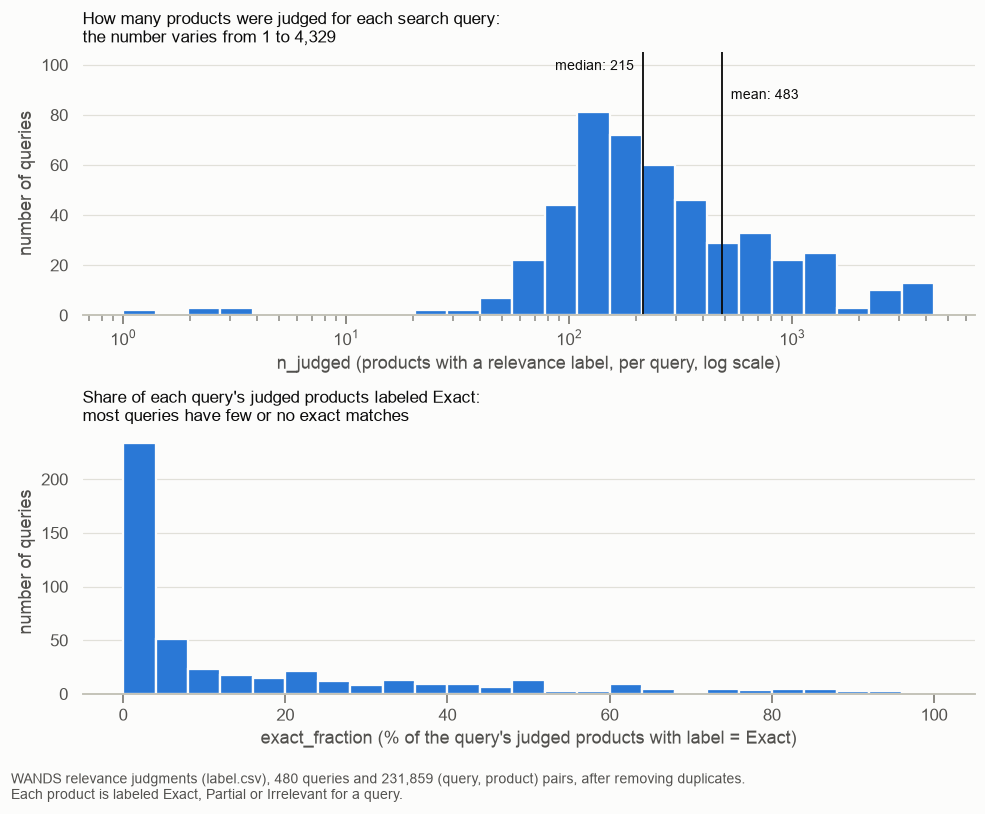

In [25]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 7))

sns.histplot(profile["n_judged"], log_scale=True, bins=25, color=plots.SERIES_1, alpha=1,
             edgecolor=plots.SURFACE, linewidth=1.5, ax=top)
top.grid(axis="x", visible=False)
top.margins(y=0.3)
top.set_title("How many products were judged for each search query:\nthe number varies from 1 to 4,329")
top.set_xlabel("n_judged (products with a relevance label, per query, log scale)")
top.set_ylabel("number of queries")
plots.reference_line(top, profile["n_judged"].median(), f"median: {profile['n_judged'].median():.0f}", ha="right")
plots.reference_line(top, profile["n_judged"].mean(), f"mean: {profile['n_judged'].mean():.0f}", y_fraction=0.82)

sns.histplot(profile["exact_fraction"] * 100, bins=range(0, 104, 4), color=plots.SERIES_1, alpha=1,
             edgecolor=plots.SURFACE, linewidth=1.5, ax=bottom)
bottom.grid(axis="x", visible=False)
bottom.set_title("Share of each query's judged products labeled Exact:\nmost queries have few or no exact matches")
bottom.set_xlabel("exact_fraction (% of the query's judged products with label = Exact)")
bottom.set_ylabel("number of queries")

fig.tight_layout()
plots.add_caption(fig, f"WANDS relevance judgments (label.csv), {len(profile)} queries and {len(unique_labels):,} "
                       "(query, product) pairs, after removing duplicates. Each product is labeled Exact, Partial or "
                       "Irrelevant for a query.", width=115)
plt.show()

**Conclusões**

- **O número de produtos julgados varia muito entre as queries:** de 1 a 4.329, com mediana de 215 e média de 483. A média esconde isso: 10% das queries concentram 47,1% dos pares.
- **A cobertura é menor do que a média sugere:** na mediana, cada query tem 0,50% do catálogo julgado (na média, 1,12%).
- **101 queries (21%) não têm nenhum Exact.** Nas 479 queries que restam depois da exclusão da Etapa 4.6, são 100. Decisão (`docs/EVALUATION.md`): o NDCG@10 cobre todas as queries, e Capped Recall@100 e MRR@10, que contam só Exact como relevante, usam as 379 queries com Exact.
- **1 query não tem nenhum produto relevante:** "drudge report", com um único produto, Irrelevant. Decisão (Etapa 4.6): ela é excluída antes da divisão.
- **Há queries que não parecem buscas por produto:** "promo codes or discounts" e "drudge report", por exemplo. Próxima etapa: observar isso na análise de erros.

**Suposições**
- Queries com poucos produtos julgados medem o sistema tão bem quanto as outras, já que cada query pesa o mesmo na nota final. Com 1 a 3 produtos julgados, isso é discutível.

**Escolhas e alternativas**
- **Escolha:** excluir "drudge report" antes da divisão (implementado em `split.relevant_queries`). **Alternativas:** mantê-la na divisão e fora das métricas que exigem um produto relevante; contá-la com nota zero.
- **Escolha:** manter as 8 queries com menos de 10 produtos julgados. **Alternativas:** exigir um mínimo de produtos julgados; reportar a nota com e sem essas queries.

### 4.4 · Perfil de `label` por produto

Quantas vezes cada produto foi julgado? Se poucos produtos concentrarem os julgamentos, o modelo veria sempre os mesmos exemplos.

In [26]:
judgments_per_product = unique_labels.groupby("product_id").size()
display(judgments_per_product.describe(percentiles=[0.5, 0.9, 0.99]).round(1).to_frame("judgments").T)

product_labels = unique_labels.groupby(["product_id", "label"]).size().unstack(fill_value=0)
print(f"products with at least one Exact:   {(product_labels['Exact'] > 0).sum():>6,}")
print(f"products with no Exact:             {(product_labels['Exact'] == 0).sum():>6,}")
print(f"products that are only Irrelevant:  {((product_labels['Exact'] == 0) & (product_labels['Partial'] == 0)).sum():>6,}")
print(f"products both Exact and Irrelevant: {((product_labels['Exact'] > 0) & (product_labels['Irrelevant'] > 0)).sum():>6,}")

,count,mean,std,min,50%,90%,99%,max
judgments,42986.0,5.4,4.4,1.0,4.0,12.0,18.0,45.0


products with at least one Exact:   20,741
products with no Exact:             22,245
products that are only Irrelevant:     983
products both Exact and Irrelevant: 13,605


**Conclusões**

- Os julgamentos não se concentram em poucos produtos: a mediana é 4 por produto, e o máximo é 45.
- **A relevância depende da query, não só do produto:** 13.605 produtos são Exact para uma query e Irrelevant para outra. Isso reforça a decisão de não usar `product_id` como feature: o modelo precisa olhar a relação entre a query e o produto.
- Só 983 produtos são Irrelevant em todas as queries em que aparecem.

**Suposições**
- O sistema precisa funcionar com produtos que não viu no treino.

**Escolhas e alternativas**
- **Escolha:** não usar `product_id` como feature. **Alternativas:** usá-lo para capturar a popularidade do produto, com risco de o modelo decorar produtos; usar sinais de popularidade que não dependem do id, como `rating_count`.

### 4.5 · `product_class` concorda com `query_class`?

Com que frequência o `product_class` de um produto contém a `query_class` da query, para cada `label`? Isso mostra o quanto a categoria ajuda a separar os rótulos e testa a decisão de não filtrar por categoria. É só uma análise: `query_class` não entra no sistema.

In [27]:
pairs = (
    unique_labels
    .merge(queries[["query_id", "query_class"]], on="query_id")
    .merge(products[["product_id", "product_class"]], on="product_id")
    .dropna(subset=["query_class", "product_class"])
)
pairs["class_match"] = [
    query_class in data.split_product_classes(product_class)
    for query_class, product_class in zip(pairs["query_class"], pairs["product_class"])
]
print(f"pairs with both values known: {len(pairs):,}")

match_by_label = pairs.groupby("label")["class_match"].agg(pairs="size", match_pct=lambda s: s.mean() * 100).round(1)
display(match_by_label)
exact_pairs = pairs[pairs["label"] == "Exact"]
print(f"Exact pairs whose product_class does not contain query_class: {(~exact_pairs['class_match']).sum():,}")

pairs with both values known: 213,745


,pairs,match_pct
label,,
Exact,23571,74.0
Irrelevant,56546,5.1
Partial,133628,54.4


Exact pairs whose product_class does not contain query_class: 6,138


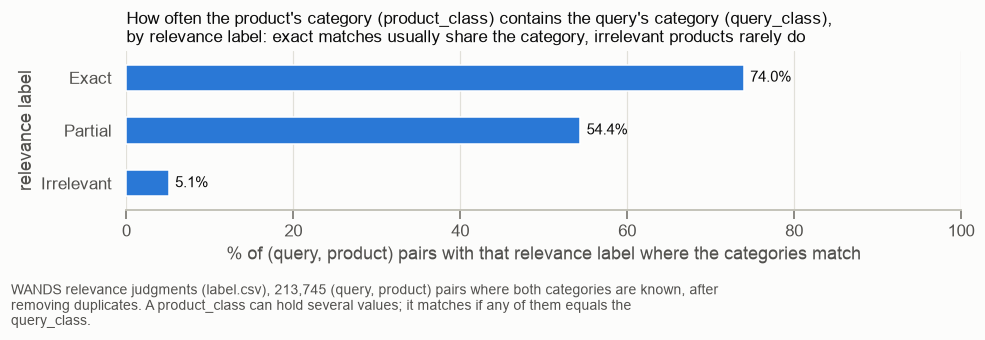

In [28]:
order = ["Exact", "Partial", "Irrelevant"]

fig, ax = plt.subplots(figsize=(9, 2.6))
sns.barplot(x=match_by_label.loc[order, "match_pct"], y=order, color=plots.SERIES_1, saturation=1, width=0.5, ax=ax)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=4, color=plots.PRIMARY_INK)
ax.set_xlim(0, 100)
ax.grid(axis="y", visible=False)
ax.set_title("How often the product's category (product_class) contains the query's category (query_class),\n"
             "by relevance label: exact matches usually share the category, irrelevant products rarely do")
ax.set_xlabel("% of (query, product) pairs with that relevance label where the categories match")
ax.set_ylabel("relevance label")
fig.tight_layout()
plots.add_caption(fig, f"WANDS relevance judgments (label.csv), {len(pairs):,} (query, product) pairs where both "
                       "categories are known, after removing duplicates. A product_class can hold several values; "
                       "it matches if any of them equals the query_class.", width=110)
plt.show()

**Conclusões**

- **A categoria é um sinal forte:** o `product_class` contém a `query_class` em 74,0% dos pares Exact, em 54,4% dos Partial e em só 5,1% dos Irrelevant. Isso sustenta testar a semelhança entre a query e o `category_hierarchy` como feature do ranking.
- **Mas não serve como filtro:** 26% dos pares Exact (6.138) têm `product_class` sem a `query_class`. Um filtro por categoria esconderia esses produtos, mesmo com a categoria certa em mãos.
- Lembrando que `query_class` não entra no sistema; esta é só uma análise.

**Suposições**
- **A força do sinal pode estar inflada.** Segundo o artigo, parte dos candidatos foi selecionada pelo `product_class` previsto para a query. A concordância entre as categorias é, em parte, consequência de como os pares foram escolhidos, e essa medição não separa os dois efeitos.
- `query_class` representa o que um modelo preveria só com o texto da busca. Por isso a análise serve de limite superior para a feature real.
- O cálculo ignora pares sem `product_class`. Um filtro por categoria também esconderia esses produtos, então os 26% subestimam o problema. Essa correção ainda não foi feita.

**Escolhas e alternativas**
- **Escolha:** não filtrar por categoria e testar a semelhança com `category_hierarchy` como feature. **Alternativas:** filtro rígido com a classe prevista; aumentar a pontuação dos produtos da classe prevista sem excluir os demais (boost); usar a classe prevista como feature; não usar categoria.

**Como usar `product_class` sem conhecer a categoria da query (proposta, ainda não medida)**

A busca não recebe `query_class`, mas `product_class` é uma coluna do produto. Basta comparar esse valor com o texto da query. Da forma mais simples à mais complexa:

1. **Texto no retrieval:** `product_class` entra no texto pesquisável. A query "gray sofas" encontra um produto com `product_class` = `Sofas|Sectionals` porque ambos têm a palavra "sofas".
2. **Feature de semelhança no ranking:** uma feature é um número que descreve o par (query, produto) para o modelo. Um exemplo é a fração das palavras da query presentes em `product_class`: em "gray sofas" e `Sofas|Sectionals`, 1 de 2 palavras, ou seja, 0,5. A semelhança entre embeddings, vetores numéricos que representam o significado de um texto, funciona de forma parecida e não exige palavras iguais.
3. **Prever o `product_class` da query:** a coincidência entre a previsão e o `product_class` do produto vira uma feature. Há duas formas:
   - **Classificação de queries** (*query classification*): um modelo aprende a prever a categoria a partir do texto da query, com `query_class` como resposta no treino. O limite são os poucos exemplos: 139 dos 188 valores de `query_class` têm menos de 3 queries. Treinar com `product_name` e `product_class` daria mais exemplos, mas nomes de produtos não são escritos como buscas.
   - **Pseudo-relevance feedback:** tratar os primeiros resultados de um retrieval inicial como relevantes e usar o `product_class` mais comum entre eles como previsão, sem treinar um classificador. O conceito vem da literatura de retrieval, não dos nossos dados, e a fonte ainda precisa ser citada; a aplicação a `product_class` é uma proposta nossa.

`query_class` nunca entra como entrada na busca, e o classificador só a usa como resposta no conjunto de treino.

**Escolha:** começar pelas formas 1 e 2, que são simples e não dependem de previsão. **Alternativas:** testar a forma 3 na validação se a análise de erros mostrar que a categoria faz falta; não usar `product_class`.


### 4.6 · Como dividir as queries

O dataset não tem divisão oficial, então definimos a nossa. Este é o raciocínio, que está formalizado em `docs/EVALUATION.md`.

**Cada query fica inteira em uma única parte** (treino, validação ou teste), qualquer que seja o número de produtos julgados. Assim, validação e teste simulam buscas que o sistema nunca viu. Se os produtos de uma query fossem separados, o modelo já teria visto essa busca no treino, e a nota sairia melhor do que na prática.

**Antes de dividir**, saem as queries sem nenhum produto `label` = Exact ou Partial, porque sem produto relevante Recall@K, MRR e NDCG@K não existem ou valem 0 para qualquer sistema. Queries quase iguais (como "leather chair" e "leather chairs", Etapa 3) formam um bloco que vai inteiro para uma parte.

**Estratificamos por duas variáveis**, porque a nota final é a média por query e queremos que as três partes tenham queries parecidas nelas. Estratificar é manter a mesma proporção de cada grupo em todas as partes. Isso exige grupos, então cada variável, que é numérica, é cortada em faixas (categorias), e as faixas das duas são cruzadas.
- `exact_share` = `Exact / (Exact + Partial)`.
  - **Tipo:** contínua, entre 0 e 1.
  - **O que mede:** entre os produtos relevantes da query (Exact ou Partial), a fração que é Exact, ou seja, correspondência perfeita. Não mede a dificuldade da query para um buscador.
  - **Motivação:** o ganho é graduado (Exact = 2, Partial = 1). Em uma query com muitos Exact, vários produtos valem 2 e é mais fácil pontuar alto; em uma com quase só Partial, um único Exact decide a nota. Se uma parte tiver por acaso muito mais queries do primeiro tipo, o sistema pontuaria mais nela sem ser melhor. Estratificar mantém a mesma mistura nas três partes. Não medimos esse efeito: pode ser verificado depois com o primeiro BM25, só em treino e validação. Deixamos o `label` Irrelevant de fora, porque o número de Irrelevant depende de quantos candidatos entraram para julgamento, não só da query.
  - **Faixas:** exatamente 0; até 5%; de 5% a 25%; acima de 25%.
- `n_judged`:
  - **Tipo:** contagem (número inteiro, de 1 a 4.329), tratada como variável numérica.
  - **O que mede:** quantos produtos têm `label` para a query, ou seja, o tamanho do conjunto julgado. Também não mede dificuldade, e conta os Irrelevant.
  - **Motivação:** ele acompanha o número de produtos relevantes da query (correlação na célula de números, abaixo), e supomos que isso afetaria métricas como Recall@K, sem termos medido esse efeito. Queremos que cada parte tenha uma mistura parecida de queries pequenas e grandes.
  - **Faixas:** 3 faixas com quantidade parecida de queries.
- **Alternativas:** usar `Exact / n_judged`, que inclui Irrelevant no denominador; usar `Exact + Partial` no lugar de `n_judged`; não cortar em faixas e distribuir as queries ordenadas pelo valor, o que não comparamos e seria mais difícil de explicar e testar.

Não estratificamos por `query_class` (a maioria dos valores tem menos de 3 queries, e a informação não existe em produção) nem pela fração de Irrelevant (daria grupos pequenos demais). Os rótulos só decidem em qual parte cada query fica; o modelo não recebe essa informação, então isso não é vazamento de dados.

As células abaixo mostram os grupos e o resultado da divisão final: proporção 60/20/20 e `seed = 87`, fixadas antes de qualquer resultado de modelo. Não fazemos simulação de seeds: com a seed fixa a divisão é determinística, e o que importa é conferir se as partes ficaram parecidas.

In [29]:
relevant = split.relevant_queries(profile)
excluded = profile.drop(relevant.index)
print(f"queries with labels: {len(profile)} | with Exact or Partial: {len(relevant)} | excluded: {len(excluded)}")
display(queries.merge(excluded, left_on="query_id", right_index=True)
        [["query_id", "query", "Exact", "Partial", "Irrelevant", "n_judged"]])

groups = split.stratification_groups(relevant)
group_table = groups.str.split("|", expand=True).set_axis(["exact_share_band", "n_judged_band"], axis=1)
print("queries per stratification group:")
display(pd.crosstab(group_table["exact_share_band"], group_table["n_judged_band"])
        .reindex(index=split.EXACT_SHARE_NAMES, columns=split.N_JUDGED_NAMES))
print("n_judged range per band:")
display(relevant.groupby(group_table["n_judged_band"])["n_judged"].agg(["min", "max", "count"]).reindex(split.N_JUDGED_NAMES))

queries with labels: 480 | with Exact or Partial: 479 | excluded: 1


,query_id,query,Exact,Partial,Irrelevant,n_judged
360,366,drudge report,0,0,1,1


queries per stratification group:


n_judged_band,low,medium,high
exact_share_band,,,
none,49,26,25
up_to_5pct,31,41,53
5_to_25pct,34,35,42
over_25pct,48,55,40


n_judged range per band:


,min,max,count
n_judged_band,,,
low,1,149,162
medium,150,340,157
high,344,4329,160


In [30]:
assignment = split.split_queries(profile, queries)
PARTS = list(split.SPLIT_FRACTIONS)
assert assignment.index.is_unique and set(assignment.index) == set(relevant.index)

per_query = relevant.assign(
    exact_share=split.exact_share(relevant),
    irrelevant_share=relevant["Irrelevant"] / relevant["n_judged"],
    split=assignment,
)
print(f"seed: {split.SPLIT_SEED} | fractions: {split.SPLIT_FRACTIONS}")
print("queries per part:")
display(per_query.groupby("split").size().reindex(PARTS).to_frame("queries").T)
print("smallest stratification group:", groups.value_counts().min(), "queries")

for column in ["n_judged", "exact_share", "irrelevant_share"]:
    print(f"{column} per part:")
    display(per_query.groupby("split")[column].describe(percentiles=[0.25, 0.5, 0.75])
            .round(3).reindex(PARTS)[["mean", "25%", "50%", "75%"]])

print("share of (query, product) pairs per label, by part:")
pairs_by_part = unique_labels.merge(assignment.rename("split"), left_on="query_id", right_index=True)
display(pd.crosstab(pairs_by_part["split"], pairs_by_part["label"], normalize="index")
        .round(3).reindex(index=PARTS, columns=profiling.LABEL_NAMES))

query_keys = queries.set_index("query_id")["query"].map(profiling.query_group_key)
near_duplicates = query_keys[query_keys.duplicated(keep=False)].index
print("near-duplicate queries and their part:")
display(queries.set_index("query_id").loc[near_duplicates, ["query"]].assign(split=assignment))

seed: 87 | fractions: {'train': 0.6, 'validation': 0.2, 'test': 0.2}
queries per part:


split,train,validation,test
queries,287,97,95


smallest stratification group: 25 queries
n_judged per part:


,mean,25%,50%,75%
split,,,,
train,464.725,126.5,217.0,547.0
validation,498.155,122.0,218.0,504.0
test,528.011,115.0,211.0,464.0


exact_share per part:


,mean,25%,50%,75%
split,,,,
train,0.204,0.003,0.063,0.321
validation,0.226,0.005,0.065,0.301
test,0.221,0.005,0.081,0.382


... (2 outputs left out)

share of (query, product) pairs per label, by part:


label,Exact,Partial,Irrelevant
split,,,
train,0.112,0.649,0.239
validation,0.116,0.589,0.295
test,0.098,0.611,0.291


near-duplicate queries and their part:


,query,split
query_id,,
26,leather chairs,validation
151,leather chair,validation


In [31]:
def rank_correlation(a: pd.Series, b: pd.Series) -> float:
    """Spearman correlation: the Pearson correlation of the ranks."""
    return a.rank().corr(b.rank())


exact_fraction = relevant["Exact"] / relevant["n_judged"]
print(f"queries analysed: {len(relevant)}")
print(f"rank correlation, n_judged vs Exact + Partial:        {rank_correlation(relevant['n_judged'], relevant['Exact'] + relevant['Partial']):.3f}")
print(f"rank correlation, n_judged vs Irrelevant:             {rank_correlation(relevant['n_judged'], relevant['Irrelevant']):.3f}")
print(f"rank correlation, n_judged vs exact_share:            {rank_correlation(relevant['n_judged'], split.exact_share(relevant)):.3f}")
print(f"rank correlation, exact_share vs Exact / n_judged:    {rank_correlation(split.exact_share(relevant), exact_fraction):.3f}")
print(f"queries with 90% or more Irrelevant products:         {(per_query['irrelevant_share'] >= 0.9).sum()}")

train_products = set(pairs_by_part.loc[pairs_by_part["split"] == "train", "product_id"])
for part in ["validation", "test"]:
    part_pairs = pairs_by_part[pairs_by_part["split"] == part]
    part_products = part_pairs["product_id"].drop_duplicates()
    print(f"{part}: {part_pairs['product_id'].isin(train_products).mean() * 100:.1f}% of the pairs have a product judged in train; "
          f"{(~part_products.isin(train_products)).sum():,} of {len(part_products):,} distinct products have no judged pair in train")

queries analysed: 479
rank correlation, n_judged vs Exact + Partial:        0.880
rank correlation, n_judged vs Irrelevant:             0.516
rank correlation, n_judged vs exact_share:            -0.013
rank correlation, exact_share vs Exact / n_judged:    0.975
queries with 90% or more Irrelevant products:         8


validation: 94.7% of the pairs have a product judged in train; 2,155 of 25,388 distinct products have no judged pair in train


test: 92.7% of the pairs have a product judged in train; 2,587 of 25,112 distinct products have no judged pair in train


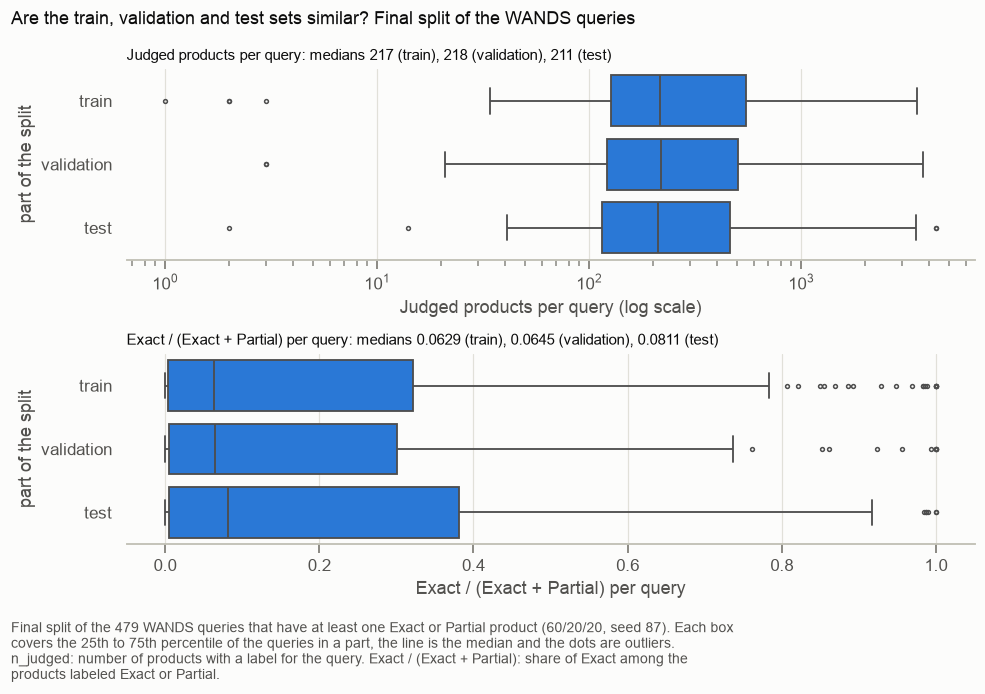

In [31]:
fig, axes = plt.subplots(2, 1, figsize=(9, 5.6))
panels = [
    ("n_judged", "Judged products per query", True),
    ("exact_share", "Exact / (Exact + Partial) per query", False),
]
for ax, (column, label, log_scale) in zip(axes, panels):
    sns.boxplot(data=per_query, x=column, y="split", order=PARTS, color=plots.SERIES_1, log_scale=log_scale,
                saturation=1, linewidth=1.2, fliersize=2.5, ax=ax)
    ax.set_xlabel(label + (" (log scale)" if log_scale else ""))
    ax.set_ylabel("part of the split")
    medians = per_query.groupby("split")[column].median().reindex(PARTS)
    ax.set_title(f"{label}: medians {medians.iloc[0]:.3g} (train), {medians.iloc[1]:.3g} (validation), {medians.iloc[2]:.3g} (test)",
                 fontsize=10)
fig.suptitle("Are the train, validation and test sets similar? Final split of the WANDS queries", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
plots.add_caption(fig, f"Final split of the {len(per_query)} WANDS queries that have at least one Exact or Partial product "
                       f"(60/20/20, seed {split.SPLIT_SEED}). Each box covers the 25th to 75th percentile of the queries in a part, "
                       "the line is the median and the dots are outliers. n_judged: number of products with a label for the query. "
                       "Exact / (Exact + Partial): share of Exact among the products labeled Exact or Partial.", width=115)
plt.show()

**Conclusões**

- **Exclusão:** 1 das 480 queries não tem produto Exact nem Partial: `query_id` 366, "drudge report", com um único par Irrelevant. Restam 479 queries.
- **Grupos viáveis:** os 12 grupos têm de 25 a 55 queries. O menor tem 25.
- **Tamanho das partes:** 287 queries em treino, 97 em validação e 95 em teste. Sem o bloco "leather chair", seriam 287, 96 e 96; as duas queries do bloco foram para a validação.
- **`n_judged`:** as medianas são parecidas nas três partes (217, 218 e 211), e os quartis também.
- **`exact_share`:** as medianas são 0,063 (treino), 0,065 (validação) e 0,081 (teste). O teste fica um pouco acima: o 3º quartil é 0,382, contra 0,321 no treino e 0,301 na validação. Em cada parte, metade das queries tem `exact_share` abaixo de 0,09.
- **Irrelevant:** a mediana da fração de Irrelevant por query é 0,074 (treino), 0,088 (validação) e 0,078 (teste). Contando pares, validação e teste têm mais Irrelevant (29,5% e 29,1%) do que o treino (23,9%). Não estratificamos por isso e não investigamos a causa.
- **`n_judged` e o número de relevantes:** a correlação de postos de `n_judged` com `Exact + Partial` é 0,880, e com `Irrelevant` é 0,516. Com `exact_share` é −0,013, então tamanho e composição são informações quase independentes. `exact_share` e `Exact / n_judged` ordenam as queries quase igual (0,975).
- **Irrelevant extremo:** 8 queries têm 90% ou mais de produtos Irrelevant.
- **Produtos compartilhados:** 94,7% dos pares da validação e 92,7% dos do teste têm um produto também julgado no treino. 2.155 dos 25.388 produtos distintos da validação e 2.587 dos 25.112 do teste não têm nenhum par julgado no treino.
- **Queries quase iguais:** "leather chair" (`query_id` 151) e "leather chairs" (26) ficaram juntas, em validação.

**Suposições**
- A exclusão antes da divisão usa Exact e Partial como relevantes, porque o NDCG@10 usa ganho graduado (Exact = 2, Partial = 1, Irrelevant = 0, ver `docs/EVALUATION.md`). Capped Recall@100 e MRR@10 contam só Exact como relevante e, por isso, não cobrem as 100 queries (das 479) sem Exact; a regra de exclusão da divisão não muda.
- Supomos que uma parte com mais queries de `exact_share` alto teria notas maiores só por isso, e que a composição dos `label` se relaciona com a dificuldade da query. Não medimos nenhuma das duas coisas com um buscador.
- Com cerca de 95 queries por parte, diferenças pequenas entre as partes são esperadas por acaso. Não fizemos teste estatístico para dizer se as diferenças acima são maiores do que isso.
- A seed (87) foi fixada antes de gerar a divisão e de qualquer resultado de modelo. Não vamos trocá-la depois de olhar as tabelas acima.
- Usar `label` para escolher a parte de cada query não é vazamento, porque o modelo não recebe essa informação. O risco é pequeno, mas a escolha usa as respostas.

**Escolhas e alternativas**
- **Escolha:** dividir por query. **Alternativas:** dividir por par (query, produto), que descartamos porque o modelo já teria visto a busca no treino.
- **Escolha:** excluir antes da divisão as queries sem Exact nem Partial. **Alternativas:** mantê-las na divisão e tirá-las só das métricas, o que deixaria o conjunto de queries com duas definições.
- **Escolha:** estratificar por `exact_share` e `n_judged`. **Alternativas:** sorteio simples, que não comparamos; `Exact / n_judged`, que inclui Irrelevant no denominador; usar só informações do texto da query, sem olhar `label`.
- **Escolha:** 60/20/20. **Alternativas:** 70/15/15, que dá mais dados ao treino, mas deixa o teste com cerca de 70 queries e a nota mais ruidosa; 80/10/10.
- **Escolha:** uma única divisão fixa com seed. **Alternativas:** validação cruzada por query sobre treino e validação juntos, que dá uma estimativa mais estável a um custo maior; o teste continuaria sendo rodado uma única vez.
- **Escolha:** queries quase iguais em um bloco. **Alternativas:** tratá-las como queries independentes, o que arrisca ter uma no treino e outra no teste.

### 4.7 · `rating_count`, `average_rating` e `review_count` por `label`

Na Etapa 2 olhamos essas colunas só por produto. Aqui juntamos com `label.csv` (sem duplicatas) para ver se os produtos Exact, Partial e Irrelevant se diferenciam nelas. Se não se diferenciarem, elas dizem pouco sobre a relevância para a query; se sim, podem ajudar o modelo de ranking. Cada linha é um par (query, produto), então um produto julgado muitas vezes pesa mais.

Medimos, para cada `label`: a fração de pares cujo produto não tem avaliação, e, entre os que têm, a distribuição de `rating_count`, `average_rating` e `review_count`.

In [31]:
rating_pairs = unique_labels.merge(products[["product_id", *rating_columns]], on="product_id")
order = ["Exact", "Partial", "Irrelevant"]
rating_pairs["has_ratings"] = rating_pairs["rating_count"].notna()
print(f"pairs: {len(rating_pairs):,}")

coverage_by_label = (
    rating_pairs.groupby("label")["has_ratings"].agg(pairs="size", without_ratings_pct=lambda s: (1 - s.mean()) * 100)
    .loc[order].round(1)
)
display(coverage_by_label)

rated_pairs = rating_pairs[rating_pairs["has_ratings"]]
stats_by_label = rated_pairs.groupby("label").agg(
    pairs=("label", "size"),
    rating_count_p25=("rating_count", lambda s: s.quantile(0.25)),
    rating_count_median=("rating_count", "median"),
    rating_count_p75=("rating_count", lambda s: s.quantile(0.75)),
    rating_count_mean=("rating_count", "mean"),
    review_count_median=("review_count", "median"),
    average_rating_mean=("average_rating", "mean"),
    average_rating_4_5_or_more_pct=("average_rating", lambda s: (s >= 4.5).mean() * 100),
).loc[order].round(2)
display(stats_by_label.T)

pairs: 231,859


,pairs,without_ratings_pct
label,,
Exact,25470,19.1
Partial,145670,24.1
Irrelevant,60719,20.5


label,Exact,Partial,Irrelevant
pairs,20616.00,110631.00,48261.00
rating_count_p25,9.00,9.00,8.00
rating_count_median,42.00,54.00,44.00
rating_count_p75,171.00,253.00,193.00
rating_count_mean,379.41,508.56,428.73
review_count_median,32.00,41.00,33.00
average_rating_mean,4.53,4.50,4.52
average_rating_4_5_or_more_pct,84.54,84.28,84.69


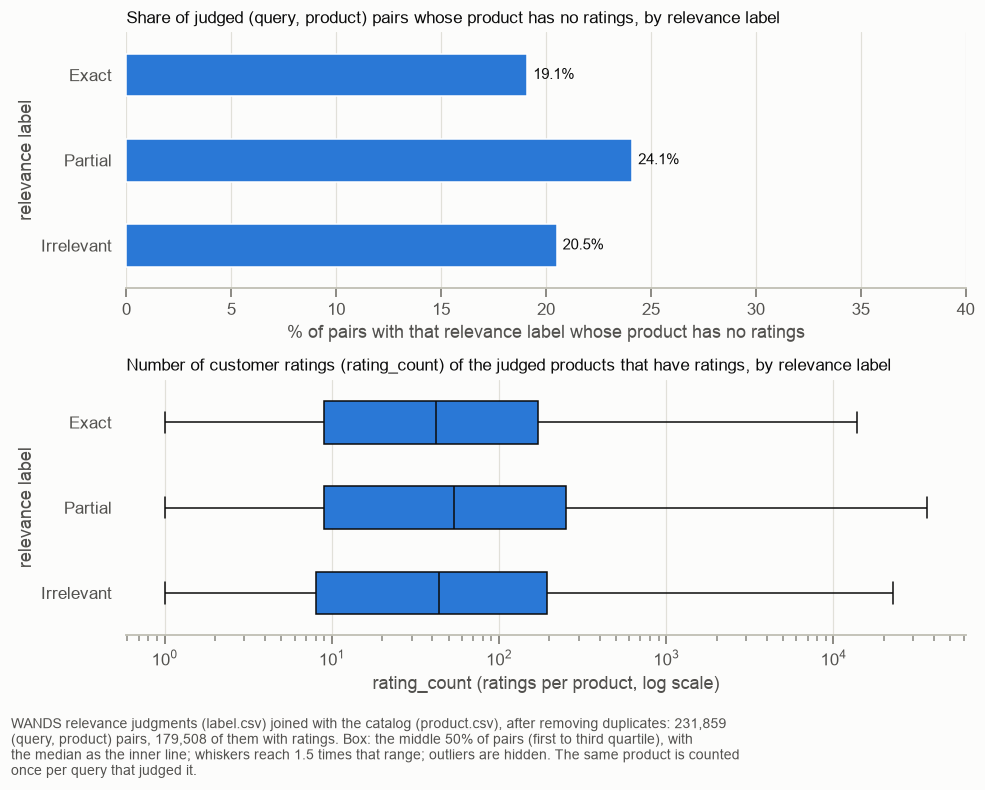

In [32]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 6.5))

sns.barplot(x=coverage_by_label["without_ratings_pct"], y=order, color=plots.SERIES_1, saturation=1, width=0.5, ax=top)
top.bar_label(top.containers[0], fmt="%.1f%%", padding=4, color=plots.PRIMARY_INK)
top.set_xlim(0, 40)
top.grid(axis="y", visible=False)
top.set_title("Share of judged (query, product) pairs whose product has no ratings, by relevance label")
top.set_xlabel("% of pairs with that relevance label whose product has no ratings")
top.set_ylabel("relevance label")

sns.boxplot(data=rated_pairs, x="rating_count", y="label", order=order, log_scale=True, showfliers=False,
            color=plots.SERIES_1, saturation=1, width=0.5, linecolor=plots.PRIMARY_INK, ax=bottom)
bottom.grid(axis="y", visible=False)
bottom.set_title("Number of customer ratings (rating_count) of the judged products that have ratings, by relevance label")
bottom.set_xlabel("rating_count (ratings per product, log scale)")
bottom.set_ylabel("relevance label")

fig.tight_layout()
plots.add_caption(fig, f"WANDS relevance judgments (label.csv) joined with the catalog (product.csv), after removing "
                       f"duplicates: {len(rating_pairs):,} (query, product) pairs, {len(rated_pairs):,} of them with "
                       "ratings. Box: the middle 50% of pairs (first to third quartile), with the median as the inner "
                       "line; whiskers reach 1.5 times that range; outliers are hidden. The same product is counted "
                       "once per query that judged it.", width=115)
plt.show()

**Conclusões**

- **Os três `label` quase não se diferenciam nessas colunas.** A mediana de `rating_count` é 42 em Exact, 54 em Partial e 44 em Irrelevant, e os quartis se sobrepõem bastante (primeiro quartil 8 ou 9 nos três; terceiro quartil de 171 a 253).
- **`average_rating`:** a média é 4,53 em Exact, 4,50 em Partial e 4,52 em Irrelevant, e a fração de pares com 4,5 ou mais estrelas é de 84,3% a 84,7%. Não há separação.
- **Sem avaliação:** 19,1% dos pares Exact, 24,1% dos Partial e 20,5% dos Irrelevant. A diferença entre `label` é de poucos pontos percentuais e não é monotônica (Partial é o maior).
- **Partial tem produtos um pouco mais avaliados** (média de `rating_count` 509 contra 379 em Exact e 429 em Irrelevant), mas Exact tem os menores valores, então `rating_count` alto não indica mais relevância nestes dados.

**Suposições**
- Os pares são os de `label.csv` sem duplicatas, e as estatísticas de avaliação usam só os pares cujo produto tem avaliação (77,4% dos pares). Os demais aparecem apenas na fração "sem avaliação".
- Os valores de avaliação são os do catálogo atual, não os do momento em que o produto foi julgado.
- O viés de pooling (Etapa 5) pode afetar a comparação: os pares foram escolhidos por retrieval, e não amostrados ao acaso.
- A significância das diferenças pequenas e a análise dentro de cada query estão na seção 4.8.

**Escolhas e alternativas**
- **Escolha (proposta):** manter `rating_count` (em log), `average_rating` e `review_count` como candidatas fracas ao modelo de ranking e decidir pela ablação na validação, em vez de assumir que ajudam. **Alternativas:** descartá-las já; usar só como desempate; usar só a feature binária `has_ratings` (1 se o produto tem avaliação, 0 se não).
- A análise dentro de cada query, que separa o efeito de popularidade do efeito de quais produtos cada query recebe, está na seção 4.8.

### 4.8 · Dentro de cada query, as colunas de avaliação acompanham o `label`?

A seção 4.7 comparou todos os pares juntos. Isso mistura dois efeitos: os produtos de uma query podem ter mais ou menos avaliações que os de outra (por exemplo, "sofa" recebe produtos muito avaliados), e esse efeito aparece como diferença entre `label` mesmo que, dentro de cada query, a avaliação não ajude a ordenar. O ranking só compara produtos da mesma query, então a pergunta que importa é a de dentro da query.

**Termos usados aqui**
- **Correlação de Spearman** (*Spearman correlation*): mede se duas variáveis crescem juntas, usando só a ordem dos valores. Vai de -1 a 1; 0 significa que uma não acompanha a outra. Ela é calculada em cada query, com a ordem Irrelevant (0) < Partial (1) < Exact (2) e o valor da coluna. Em empates, usa-se a posição média.
- **Intervalo de confiança por bootstrap** (*bootstrap confidence interval*): sorteamos, com reposição, as queries e recalculamos a média das correlações 2.000 vezes. O intervalo de 95% vai do percentil 2,5 ao 97,5 dessas médias. Se ele contém 0, não distinguimos a média de 0. A unidade sorteada é a query, porque pares da mesma query não são independentes.

Usamos só queries com pelo menos 20 pares com valor conhecido e correlação definida. `has_ratings` (1 se o produto tem avaliação, 0 se não) usa todos os pares.

In [33]:
BOOTSTRAP_SEED = 0
MIN_PAIRS_PER_QUERY = 20

rating_pairs["log10_rating_count"] = np.log10(rating_pairs["rating_count"])
rating_pairs["has_ratings_flag"] = rating_pairs["has_ratings"].astype(float)
within_query_columns = ["log10_rating_count", "average_rating", "review_count", "has_ratings_flag"]

correlations = {
    column: profiling.within_query_spearman(rating_pairs, column, min_pairs=MIN_PAIRS_PER_QUERY)
    for column in within_query_columns
}
rows = []
for column, values in correlations.items():
    low, high = profiling.bootstrap_mean_ci(values, seed=BOOTSTRAP_SEED)
    rows.append({
        "column": column, "queries": len(values), "mean": values.mean(), "median": values.median(),
        "ci_low": low, "ci_high": high, "queries_positive_pct": (values > 0).mean() * 100,
        "queries_negative_pct": (values < 0).mean() * 100,
    })
within_query = pd.DataFrame(rows).set_index("column")
display(within_query.round(3))
print(f"queries with at least {MIN_PAIRS_PER_QUERY} judged pairs: {(profile['n_judged'] >= MIN_PAIRS_PER_QUERY).sum()}")

,queries,mean,median,ci_low,ci_high,queries_positive_pct,queries_negative_pct
column,,,,,,,
log10_rating_count,449,0.012,0.018,-0.006,0.030,53.007,46.993
average_rating,449,0.001,-0.001,-0.012,0.014,47.884,50.557
review_count,449,0.011,0.022,-0.007,0.030,53.898,46.102
has_ratings_flag,451,0.017,0.008,0.002,0.031,51.220,46.120


queries with at least 20 judged pairs: 471


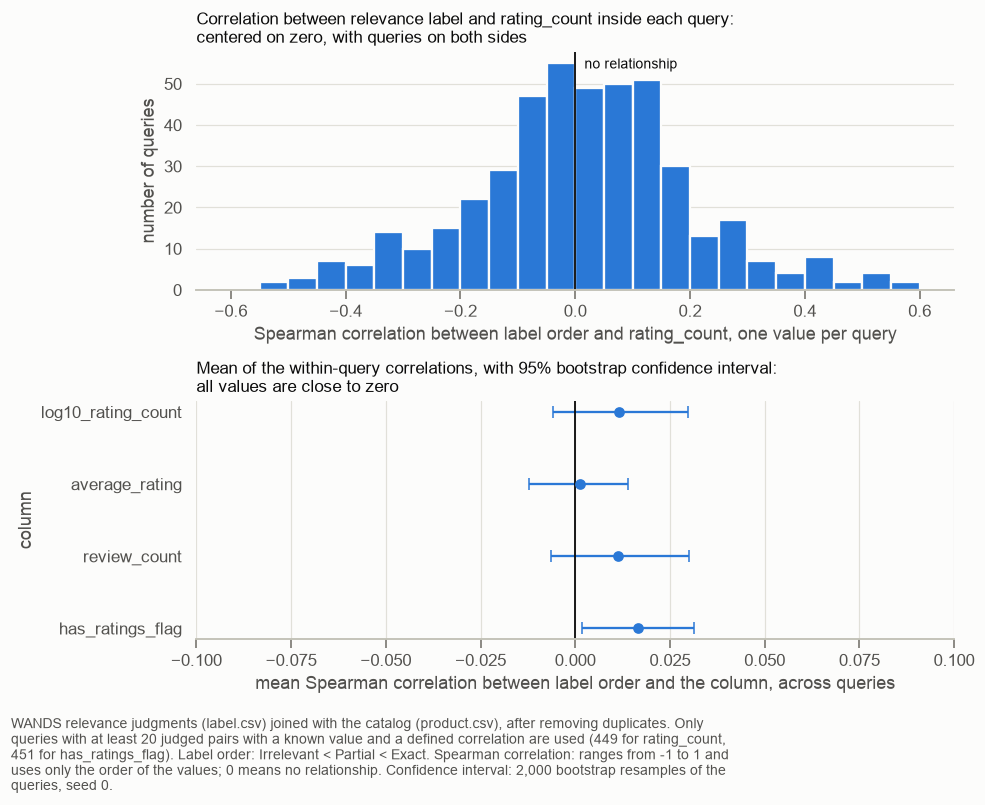

In [34]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 6.5))

sns.histplot(correlations["log10_rating_count"], bins=np.arange(-0.6, 0.65, 0.05), color=plots.SERIES_1, alpha=1,
             edgecolor=plots.SURFACE, linewidth=1.5, ax=top)
top.grid(axis="x", visible=False)
top.set_title("Correlation between relevance label and rating_count inside each query:\n"
              "centered on zero, with queries on both sides")
top.set_xlabel("Spearman correlation between label order and rating_count, one value per query")
top.set_ylabel("number of queries")
plots.reference_line(top, 0, "no relationship")

plot_data = within_query.reset_index()
bottom.errorbar(plot_data["mean"], range(len(plot_data)), xerr=[plot_data["mean"] - plot_data["ci_low"], plot_data["ci_high"] - plot_data["mean"]],
                fmt="o", color=plots.SERIES_1, ecolor=plots.SERIES_1, capsize=4)
bottom.set_yticks(range(len(plot_data)), plot_data["column"])
bottom.invert_yaxis()
bottom.axvline(0, color=plots.PRIMARY_INK, linewidth=1.2)
bottom.grid(axis="y", visible=False)
bottom.set_xlim(-0.1, 0.1)
bottom.set_title("Mean of the within-query correlations, with 95% bootstrap confidence interval:\n"
                 "all values are close to zero")
bottom.set_xlabel("mean Spearman correlation between label order and the column, across queries")
bottom.set_ylabel("column")

fig.tight_layout()
plots.add_caption(fig, "WANDS relevance judgments (label.csv) joined with the catalog (product.csv), after removing "
                       f"duplicates. Only queries with at least {MIN_PAIRS_PER_QUERY} judged pairs with a known value and a "
                       "defined correlation are used (449 for rating_count, 451 for has_ratings_flag). Label order: Irrelevant < Partial < Exact. "
                       "Spearman correlation: ranges from -1 to 1 and uses only the order of the values; 0 means no relationship. "
                       "Confidence interval: 2,000 bootstrap resamples of the queries, seed 0.", width=115)
plt.show()

**Conclusões**

- **Sem relação clara:** dentro da query, as colunas de avaliação não acompanham o `label`. Os intervalos contêm 0, exceto o de `has_ratings_flag` (`has_ratings` em formato numérico), que passa por pouco e tem efeito minúsculo.
- **Direção instável:** a correlação de `rating_count` é positiva em 53,0% das queries e negativa em 47,0%.
- **Queries individuais variam muito:** as correlações de `rating_count` vão de cerca de -0,55 a 0,6, e a média perto de zero vem de queries que se compensam. Não separamos quanto disso é ruído de poucos pares.
- **Em relação à seção 4.7:** a diferença entre as medianas de `rating_count` por `label` (42, 54 e 44) não aparece dentro da query. Uma explicação possível, que não testamos, é que ela vem de quais produtos cada query recebe.

**Suposições**
- A correlação de Spearman só vê relações monótonas e usa a ordem Irrelevant < Partial < Exact, com espaços iguais. Uma relação em formato de U (por exemplo, produtos muito populares e muito raros mais relevantes) não apareceria.
- Queries com poucos pares ficam de fora: 449 das 471 queries com pelo menos 20 pares julgados entram na análise de `rating_count`, pois algumas ficam sem correlação definida ou com poucos pares com avaliação. Elas podem ser diferentes das demais.
- O intervalo trata as queries como independentes entre si. Produtos repetidos em várias queries podem fazer o intervalo real ser um pouco maior.
- Medimos cada coluna sozinha. Um modelo pode usar `rating_count` em interação com outras features, o que esta análise não captura.

**Escolhas e alternativas**
- **Escolha (proposta):** não esperar ganho do ranking vindo de `rating_count`, `average_rating` e `review_count` sozinhos, mas manter `rating_count` e `review_count` (em log) e `has_ratings` na ablação, para confirmar na métrica final. **Alternativas:** descartar as três colunas já; usar só `has_ratings`; testar interações com features de texto.
- **Outras formas de medir:** média de NDCG de um ranking só por `rating_count` contra um ranking aleatório; teste de permutação dos `label` dentro de cada query; regressão do `label` em `rating_count` com efeito fixo de query.

## Etapa 5 · Pontos que afetam a avaliação

### 5.1 · Viés de pooling

**Pooling** é a forma comum de montar um gabarito de busca: como não dá para julgar 43 mil produtos para cada query, as pessoas julgam só os candidatos que algum buscador retornou. O efeito colateral é que produtos que aquele buscador não encontrou ficam sem rótulo.

O [artigo do WANDS](https://easychair.org/publications/preprint/wm4R) confirma o pooling: os candidatos vieram de cliques e carrinho, do Solr, de uma busca neural e do `product_class` previsto para a query. O dataset não informa de onde veio cada par. Por isso olhamos dois sinais indiretos:
1. Os produtos julgados têm mais palavras em comum com a query do que produtos aleatórios?
2. Dos produtos que contêm todas as palavras da query, quantos foram julgados?

O texto do produto aqui é `product_name`, `product_class` e `category_hierarchy`.

In [35]:
catalog_text = (
    products["product_name"].fillna("") + " "
    + products["product_class"].fillna("") + " "
    + products["category_hierarchy"].fillna("")
)
tokens_by_product = dict(zip(products["product_id"], catalog_text.map(profiling.simple_tokens)))
tokens_by_query = dict(zip(queries["query_id"], queries["query"].map(profiling.simple_tokens)))

overlap_rows = unique_labels[["query_id", "product_id", "label"]].copy()
overlap_rows["overlap"] = [
    profiling.token_overlap(tokens_by_query[q], tokens_by_product[p])
    for q, p in zip(overlap_rows["query_id"], overlap_rows["product_id"])
]

N_RANDOM_PRODUCTS = 200
rng = np.random.default_rng(SAMPLE_SEED)
product_ids = products["product_id"].to_numpy()
random_overlap = pd.Series({
    query_id: np.mean([
        profiling.token_overlap(query_tokens, tokens_by_product[p])
        for p in rng.choice(product_ids, N_RANDOM_PRODUCTS, replace=False)
    ])
    for query_id, query_tokens in tokens_by_query.items()
})
judged_overlap = overlap_rows.groupby("query_id")["overlap"].mean()

print(f"mean overlap per query, median across queries, judged products: {judged_overlap.median():.3f}")
print(f"mean overlap per query, median across queries, random products: {random_overlap.median():.3f}")

by_label = overlap_rows.groupby("label")["overlap"].agg(
    pairs="size",
    mean_overlap="mean",
    zero_overlap_pct=lambda s: (s == 0).mean() * 100,
).round(3)
display(by_label.loc[["Exact", "Partial", "Irrelevant"]])

inverted_index = {}
for product_id, tokens in tokens_by_product.items():
    for token in tokens:
        inverted_index.setdefault(token, set()).add(product_id)

judged_by_query = unique_labels.groupby("query_id")["product_id"].agg(set)
coverage_rows = []
for query_id, query_tokens in tokens_by_query.items():
    postings = [inverted_index.get(token, set()) for token in query_tokens]
    matching = set.intersection(*postings) if postings else set()
    coverage_rows.append({
        "query_id": query_id,
        "all_tokens_match": len(matching),
        "matches_judged": len(matching & judged_by_query.get(query_id, set())),
    })
coverage = pd.DataFrame(coverage_rows).set_index("query_id")
with_matches = coverage[coverage["all_tokens_match"] > 0]
judged_share = with_matches["matches_judged"] / with_matches["all_tokens_match"] * 100

print(f"queries with at least one product matching all tokens: {len(with_matches)}")
print(f"products matching all tokens, summed over queries:     {with_matches['all_tokens_match'].sum():,}")
print(f"of those, judged for that query:                       {with_matches['matches_judged'].sum():,}")
print(f"share of matches judged per query, median:             {judged_share.median():.1f}%")
print(f"queries where every match was judged:                  {(judged_share == 100).sum()}")

mean overlap per query, median across queries, judged products: 0.485
mean overlap per query, median across queries, random products: 0.018


,pairs,mean_overlap,zero_overlap_pct
label,,,
Exact,25470,0.672,4.908
Partial,145670,0.491,2.732
Irrelevant,60719,0.424,11.545


queries with at least one product matching all tokens: 233
products matching all tokens, summed over queries:     12,756
of those, judged for that query:                       10,539
share of matches judged per query, median:             100.0%
queries where every match was judged:                  193


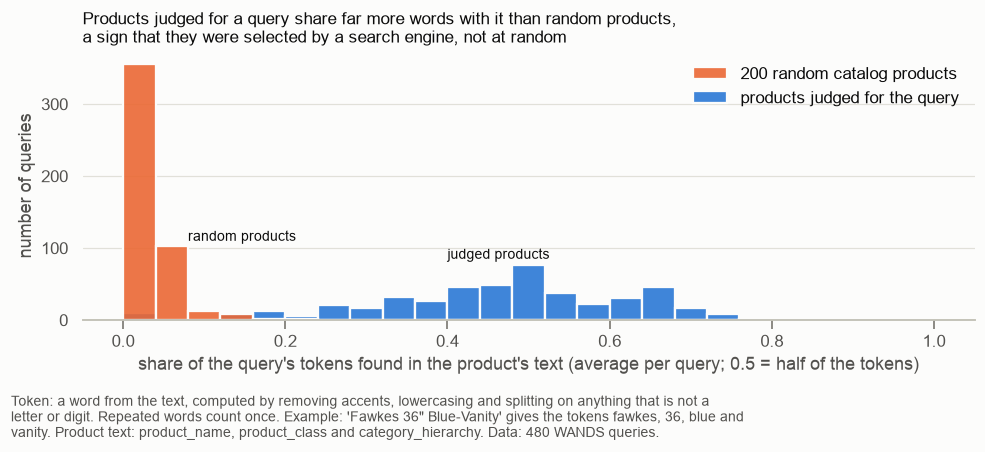

In [36]:
comparison = pd.concat([
    pd.DataFrame({"overlap": random_overlap, "products": f"{N_RANDOM_PRODUCTS} random catalog products"}),
    pd.DataFrame({"overlap": judged_overlap, "products": "products judged for the query"}),
])

fig, ax = plt.subplots(figsize=(9, 3.6))
sns.histplot(comparison, x="overlap", hue="products", bins=np.arange(0, 1.04, 0.04), multiple="layer", alpha=0.9,
             palette={f"{N_RANDOM_PRODUCTS} random catalog products": plots.SERIES_2, "products judged for the query": plots.SERIES_1},
             edgecolor=plots.SURFACE, linewidth=1.5, ax=ax)
ax.grid(axis="x", visible=False)
ax.set_title("Products judged for a query share far more words with it than random products,\n"
             "a sign that they were selected by a search engine, not at random")
ax.set_xlabel("share of the query's tokens found in the product's text (average per query; 0.5 = half of the tokens)")
ax.set_ylabel("number of queries")
ax.annotate("random products", xy=(0.08, 110), color=plots.PRIMARY_INK, fontsize=9)
ax.annotate("judged products", xy=(0.40, 85), color=plots.PRIMARY_INK, fontsize=9)
sns.move_legend(ax, "upper right", title=None)
fig.tight_layout()
plots.add_caption(fig, plots.TOKEN_DEFINITION + " Product text: product_name, product_class and category_hierarchy. "
                       f"Data: {len(queries)} WANDS queries.", width=115)
plt.show()

**Conclusões**

- **Os produtos julgados não são uma amostra aleatória:** em média, têm 48,5% das palavras da query, contra 1,8% de produtos aleatórios (medianas entre as queries). Isso é coerente com o que o artigo descreve: parte dos candidatos veio de buscadores.
- **O gabarito cobre bem os produtos que têm todas as palavras da query:** há 12.756 casos assim, e 10.539 (83%) foram julgados. Em 193 das 233 queries com algum caso, todos foram julgados. Um buscador por palavras deve encontrar poucos produtos sem rótulo.
- **Um sistema semântico pode ser prejudicado:** ele pode retornar produtos relevantes que não têm as palavras da query, e é mais provável que estes estejam sem rótulo. Por isso reportar a porcentagem de resultados com rótulo é essencial na comparação.
- **Mas o pooling não foi só por palavras:** 4,9% dos pares Exact, 2,7% dos Partial e 11,5% dos Irrelevant não têm nenhuma palavra em comum com a query. Esse texto do produto não inclui `product_description` nem `product_features`, então parte desses casos pode ter a palavra nessas colunas. O artigo também explica parte disso: os candidatos vieram ainda de cliques, de uma busca neural e da classe prevista para a query.
- **Só palavras em comum não bastam para ordenar:** a média é 0,672 em Exact, 0,491 em Partial e 0,424 em Irrelevant. Os Irrelevant também têm muitas palavras da query, e isso justifica um modelo de ranking com outros sinais.
- 247 das 480 queries não têm nenhum produto com todas as palavras nesse texto.

**Suposições**
- Palavras em comum servem como indício da forma de seleção. O artigo confirma o pooling, mas não informa de onde veio cada par.
- **O texto do produto aqui só tem `product_name`, `product_class` e `category_hierarchy`.** A conclusão sobre a cobertura vale para esse texto; um buscador que também use `product_description` ou `product_features` pode encontrar muito mais produtos sem rótulo. Essa medição ainda não foi feita.
- Palavras são comparadas sem tratar plural nem remover palavras como "and" e "for".
- Produtos aleatórios representam o catálogo. Esse catálogo já é uma amostra de produtos ligados às queries, segundo o artigo, e não a loja inteira.
- Os anotadores viram também a imagem e a página do produto, que não estão no dataset. Alguns rótulos podem depender de informação que nenhum sistema aqui consegue ver.

**Escolhas e alternativas**
- **Escolha (decidida em `docs/EVALUATION.md`):** contar produto sem rótulo com ganho 0 na nota principal (NDCG@10) e reportar judged@10, a fração dos 10 primeiros resultados que têm rótulo. **Alternativas:** ignorar os produtos sem rótulo no cálculo; usar métricas feitas para julgamentos incompletos, como bpref; julgar à mão uma amostra dos resultados sem rótulo.
- **Escolha:** usar a fração de palavras da query encontradas no produto. **Alternativas:** BM25, que dá menos peso a palavras comuns; contar só palavras raras; medir com o primeiro BM25 quantos dos K primeiros resultados têm rótulo.

### 5.2 · Normalização de texto

O que já vem pronto e o que o processamento precisa tratar? Query e produto precisam passar pelo mesmo tratamento, senão palavras iguais não se encontram. Também vemos quais palavras das queries não existem no catálogo, porque um buscador por palavras não consegue encontrá-las.

In [37]:
text_columns = {"product_name": products["product_name"], "product_description": products["product_description"].dropna(), "query": queries["query"]}

rows = {}
for name, column in text_columns.items():
    rows[name] = {
        "rows": len(column),
        "has_uppercase": column.str.contains(r"[A-Z]").sum(),
        "spaced_comma": column.str.contains(" , ", regex=False).sum(),
        "two_apostrophes": column.str.contains("''", regex=False).sum(),
        "double_quote": column.str.contains('"', regex=False).sum(),
        "html_entity": column.str.contains(r"&[a-z]+;").sum(),
        "non_ascii": column.str.contains(r"[^\x00-\x7f]").sum(),
    }
display(pd.DataFrame(rows).T)

non_ascii_counts = Counter(
    char for text in pd.concat([products["product_name"], products["product_description"].dropna()])
    for char in text if ord(char) > 127
)
print("most common non-ASCII characters:", non_ascii_counts.most_common(10))

catalog_vocabulary = set(inverted_index)
for text in products["product_description"].dropna():
    catalog_vocabulary |= profiling.simple_tokens(text)
print(f"catalog vocabulary size: {len(catalog_vocabulary):,}")

missing_tokens = {q: tokens - catalog_vocabulary for q, tokens in tokens_by_query.items()}
queries_with_missing = {q: sorted(t) for q, t in missing_tokens.items() if t}
print(f"queries with a token missing from the catalog: {len(queries_with_missing)}")
display(pd.DataFrame({
    "query": queries.set_index("query_id").loc[list(queries_with_missing), "query"],
    "missing_tokens": pd.Series(queries_with_missing),
}))

,rows,has_uppercase,spaced_comma,two_apostrophes,double_quote,html_entity,non_ascii
product_name,42994,0,935,10291,0,0,918
product_description,36986,0,30929,3935,0,0,6882
query,480,0,1,0,3,0,0


most common non-ASCII characters: [('’', 5707), ('é', 2051), ('–', 1006), ('”', 999), ('®', 691), ('™', 487), ('°', 378), ('—', 364), ('“', 301), ('â', 190)]


catalog vocabulary size: 46,762
queries with a token missing from the catalog: 36


,query,missing_tokens
20,foutains with brick look,[foutains]
23,stoneford end tables white and wood,[stoneford]
62,7qt slow cooker,[7qt]
77,sancroft armchair,[sancroft]
78,dorel vanity,[dorel]
87,vlad modular sectional,[vlad]
90,filaret outdoor sofa,[filaret]
98,gracie oaks 62 oller 14 ceiling fan,[oller]
179,promo codes or discounts,"[discounts, promo]"
190,benjiamino faux leather power lift chair,[benjiamino]


**Conclusões**

- **Já vem pronto:** o texto está em minúsculas e sem entidades HTML.
- **Acentos precisam de tratamento:** as queries não têm caracteres não ASCII, mas 918 valores de `product_name` e 6.882 de `product_description` têm, como `é` (2.051 vezes). Sem tratamento, "decor" não encontra "décor". Proposta: remover acentos de query e produto. `profiling.simple_tokens` já faz isso, e a correção mudou pouco os números desta etapa.
- **Polegadas se resolvem com o mesmo tratamento:** `36"` na query e `18 ''` em `product_name` (10.291 valores têm `''`) viram só o número quando a pontuação é descartada. Isso responde à pergunta da Etapa 3, mas perde a informação de que o número é uma medida.
- **Proposta:** query e produto passam pelo mesmo processamento, sempre.
- **36 queries (7,5%) têm palavras que não existem no catálogo**, considerando `product_name`, `product_class`, `category_hierarchy` e `product_description`, mas não `product_features`. Lendo a lista, vemos erros de digitação ("foutains", "biycicle", "ligth"), nomes próprios ("stoneford", "filaret"), palavras grudadas ("roomtables", "7qt") e outras lojas ("lowes", "urban outfitters"). Essa classificação é nossa leitura.
- **Um buscador só por palavras não encontra essas palavras.** É um argumento para comparar com uma abordagem semântica ou híbrida, como o desafio pede.

**Suposições**
- Palavras fora do catálogo são medidas sem `product_features`, então algumas podem existir nessa coluna.
- A classificação das palavras ausentes é uma leitura nossa.

**Escolhas e alternativas**
- **Escolha:** remover acentos e descartar pontuação, igual em query e produto (proposta). **Alternativas:** manter os acentos; indexar as duas formas; usar stemming ou lematização para unir singular e plural.
- **Escolha:** reduzir medidas ao número. **Alternativas:** padronizar as unidades, de modo que `36"` e `36 ''` virem `36 inch`; manter a unidade como palavra separada.